In [3]:
# Core libraries
import pandas as pd
import numpy as np
from datetime import datetime

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Settings
pd.set_option('display.max_columns', None)
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('coolwarm')

In [4]:
# ## 2. Load Data

DATA_PATH = '../data/processed/'
FILE_NAME = 'weather_history_hourly.csv'

df = pd.read_csv(f'{DATA_PATH}{FILE_NAME}')

print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Memory: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

Shape: 263,160 rows × 38 columns
Memory: 209.48 MB


In [7]:
# Preview data
df.tail(10)

,datetime,temperature_2m,apparent_temperature,dewpoint_2m,relative_humidity_2m,pressure_msl,precipitation,rain,snowfall,windspeed_10m,winddirection_10m,cloudcover,weathercode,location,country,run_date,run_timestamp,data_type,date,hour,year,month,month_name,day_of_week,avg_temp_for_hour,min_temp_for_hour,max_temp_for_hour,min_temp_day,max_temp_day,avg_temp_day,temp_7day_rolling_avg,temp_24hour_rolling_avg,temp_30day_rolling_avg,humidity_7day_rolling_avg,humidity_24hour_rolling_avg,temp_change_1hour,temp_change_24hour,last_updated
263150,2026-01-01 14:00:00,5.9,1.2,0.6,69,1006.8,0.0,0.0,0.0,19.0,301,97,3,Manchester,UK,2026-01-02,2026-01-02 19:30:15.671372,actual,2026-01-01,14,2026,1,January,Thursday,13.448,-0.4,36.0,2.7,6.2,4.771,4.296,4.721,6.942,82.512,78.125,-0.3,1.2,2026-01-02 19:30:21.426025
263151,2026-01-01 15:00:00,5.5,0.7,0.2,69,1006.5,0.0,0.0,0.0,18.6,298,98,3,Manchester,UK,2026-01-02,2026-01-02 19:30:15.671372,actual,2026-01-01,15,2026,1,January,Thursday,13.343,-2.5,33.2,2.7,6.2,4.771,4.296,4.779,6.938,82.476,77.875,-0.4,1.4,2026-01-02 19:30:21.426025
263152,2026-01-01 16:00:00,4.8,0.3,0.1,71,1006.2,0.0,0.0,0.0,16.4,293,63,2,Manchester,UK,2026-01-02,2026-01-02 19:30:15.671372,actual,2026-01-01,16,2026,1,January,Thursday,12.998,-4.3,33.8,2.7,6.2,4.771,4.296,4.850,6.934,82.440,77.542,-0.7,1.7,2026-01-02 19:30:21.426025
263153,2026-01-01 17:00:00,4.5,-0.0,-0.6,70,1005.7,0.0,0.0,0.0,16.0,296,39,1,Manchester,UK,2026-01-02,2026-01-02 19:30:15.671372,actual,2026-01-01,17,2026,1,January,Thursday,12.499,-4.4,34.0,2.7,6.2,4.771,4.295,4.904,6.930,82.405,77.125,-0.3,1.3,2026-01-02 19:30:21.426025
263154,2026-01-01 18:00:00,4.6,0.0,-0.1,72,1005.7,0.0,0.0,0.0,16.7,304,43,1,Manchester,UK,2026-01-02,2026-01-02 19:30:15.671372,actual,2026-01-01,18,2026,1,January,Thursday,11.892,-4.2,33.0,2.7,6.2,4.771,4.296,4.938,6.927,82.375,76.958,0.1,0.8,2026-01-02 19:30:21.426025
263155,2026-01-01 19:00:00,4.2,-0.4,-1.4,67,1005.7,0.0,0.0,0.0,16.0,313,46,1,Manchester,UK,2026-01-02,2026-01-02 19:30:15.671372,actual,2026-01-01,19,2026,1,January,Thursday,11.191,-4.7,30.2,2.7,6.2,4.771,4.296,4.971,6.924,82.310,76.542,-0.4,0.8,2026-01-02 19:30:21.426025
263156,2026-01-01 20:00:00,3.5,-1.0,-2.2,66,1006.0,0.0,0.0,0.0,14.3,311,95,3,Manchester,UK,2026-01-02,2026-01-02 19:30:15.671372,actual,2026-01-01,20,2026,1,January,Thursday,10.511,-4.9,27.8,2.7,6.2,4.771,4.293,4.958,6.920,82.232,76.125,-0.7,-0.3,2026-01-02 19:30:21.426025
263157,2026-01-01 21:00:00,3.1,-1.3,-2.6,66,1006.4,0.0,0.0,0.0,12.7,306,48,1,Manchester,UK,2026-01-02,2026-01-02 19:30:15.671372,actual,2026-01-01,21,2026,1,January,Thursday,9.983,-6.2,26.2,2.7,6.2,4.771,4.287,4.908,6.916,82.155,75.708,-0.4,-1.2,2026-01-02 19:30:21.426025
263158,2026-01-01 22:00:00,3.0,-1.1,-2.7,67,1006.0,0.0,0.0,0.0,10.5,295,21,1,Manchester,UK,2026-01-02,2026-01-02 19:30:15.671372,actual,2026-01-01,22,2026,1,January,Thursday,9.607,-7.4,25.4,2.7,6.2,4.771,4.281,4.842,6.912,82.083,75.333,-0.1,-1.6,2026-01-02 19:30:21.426025
263159,2026-01-01 23:00:00,2.7,-1.2,-2.8,68,1005.7,0.0,0.0,0.0,9.4,290,100,3,Manchester,UK,2026-01-02,2026-01-02 19:30:15.671372,actual,2026-01-01,23,2026,1,January,Thursday,9.298,-7.8,25.3,2.7,6.2,4.771,4.273,4.771,6.909,82.018,74.958,-0.3,-1.7,2026-01-02 19:30:21.426025


In [27]:
# Column names and types
df.dtypes

datetime                        object
temperature_2m                 float64
apparent_temperature           float64
dewpoint_2m                    float64
relative_humidity_2m             int64
pressure_msl                   float64
precipitation                  float64
rain                           float64
snowfall                       float64
windspeed_10m                  float64
winddirection_10m                int64
cloudcover                       int64
weathercode                      int64
location                        object
country                         object
run_date                        object
run_timestamp                   object
data_type                       object
date                            object
hour                             int64
year                             int64
month                            int64
month_name                      object
day_of_week                     object
avg_temp_for_hour              float64
min_temp_for_hour        

In [28]:
# Quick stats
df.describe()

,temperature_2m,apparent_temperature,dewpoint_2m,relative_humidity_2m,pressure_msl,precipitation,rain,snowfall,windspeed_10m,winddirection_10m,cloudcover,weathercode,hour,year,month,avg_temp_for_hour,min_temp_for_hour,max_temp_for_hour,min_temp_day,max_temp_day,avg_temp_day,temp_7day_rolling_avg,temp_24hour_rolling_avg,temp_30day_rolling_avg,humidity_7day_rolling_avg,humidity_24hour_rolling_avg,temp_change_1hour,temp_change_24hour
count,263160.000000,263160.000000,263160.000000,263160.000000,263160.000000,263160.000000,263160.000000,263160.000000,263160.000000,263160.000000,263160.000000,263160.000000,263160.0000,263160.000000,263160.000000,263160.000000,263160.000000,263160.000000,263160.000000,263160.000000,263160.000000,263160.000000,263160.000000,263160.000000,263160.000000,263160.000000,263155.000000,263040.000000
mean,10.808113,8.129175,7.163571,79.769194,1014.137516,0.117853,0.115703,0.001507,14.735053,191.824111,69.823176,13.415812,11.5000,2022.501140,6.519380,10.808133,-4.627500,27.881667,7.420876,14.108317,10.808110,10.812592,10.808371,10.814367,79.779898,79.772675,-0.000051,-0.000975
std,5.728080,6.863113,4.850123,13.713955,12.036437,0.422588,0.418047,0.033990,7.941570,91.093934,37.391408,21.471733,6.9222,1.709429,3.450221,1.916303,2.228343,4.994823,4.879361,5.850742,5.196217,4.850416,5.210341,4.511797,7.660772,9.367209,0.789174,2.674368
min,-10.300000,-15.700000,-12.600000,17.000000,953.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,2020.000000,1.000000,7.982000,-10.300000,19.300000,-10.300000,-1.100000,-4.783000,-2.180000,-6.012000,1.846000,47.274000,32.375000,-7.000000,-16.300000
25%,6.800000,3.000000,3.700000,72.000000,1006.900000,0.000000,0.000000,0.000000,8.600000,117.000000,36.000000,1.000000,5.7500,2021.000000,4.000000,9.196250,-5.500000,23.675000,3.800000,9.900000,6.971000,7.089000,6.983000,6.785000,75.542000,74.125000,-0.400000,-1.600000
50%,10.700000,7.800000,7.400000,83.000000,1015.300000,0.000000,0.000000,0.000000,13.500000,213.000000,95.000000,3.000000,11.5000,2023.000000,7.000000,10.459000,-4.800000,27.800000,7.600000,13.900000,10.779000,10.582000,10.792000,10.475000,80.673000,80.833000,0.000000,0.000000
75%,14.800000,13.000000,10.800000,90.000000,1022.500000,0.000000,0.000000,0.000000,19.600000,258.000000,100.000000,3.000000,17.2500,2024.000000,10.000000,12.401500,-3.100000,32.225000,11.200000,18.200000,14.763000,14.804000,14.779000,14.816000,85.233500,86.708000,0.400000,1.600000
max,37.900000,36.900000,22.300000,100.000000,1049.700000,14.700000,14.700000,3.780000,68.000000,360.000000,100.000000,75.000000,23.0000,2026.000000,12.000000,14.923000,0.000000,37.900000,23.600000,37.900000,29.075000,24.886000,29.188000,21.676000,98.000000,99.542000,6.000000,14.800000


In [29]:
# Check missing values
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)

missing_df = pd.DataFrame({
    'missing_count': missing,
    'missing_pct': missing_pct
}).sort_values('missing_count', ascending=False)

# Show only columns with missing data
missing_df[missing_df['missing_count'] > 0]

,missing_count,missing_pct
temp_change_24hour,120,0.05
temp_change_1hour,5,0.00


In [30]:
# Fill missing values using mean of before and after (interpolation)
df['temp_change_1hour'] = df.groupby('location')['temp_change_1hour'].transform(
    lambda x: x.interpolate(method='linear')
)

df['temp_change_24hour'] = df.groupby('location')['temp_change_24hour'].transform(
    lambda x: x.interpolate(method='linear')
)

# Verify fix
print("Missing values after fix:")
print(df[['temp_change_1hour', 'temp_change_24hour']].isnull().sum())

Missing values after fix:
temp_change_1hour       5
temp_change_24hour    120
dtype: int64


In [31]:
# Step 1: Interpolate (fills gaps in the middle)
if 'temp_change_1hour' in df.columns:
    df['temp_change_1hour'] = df.groupby('location')['temp_change_1hour'].transform(
        lambda x: x.interpolate(method='linear')
    )

if 'temp_change_24hour' in df.columns:
    df['temp_change_24hour'] = df.groupby('location')['temp_change_24hour'].transform(
        lambda x: x.interpolate(method='linear')
    )

# Step 2: Fill edges (fills gaps at start/end)
if 'temp_change_1hour' in df.columns:
    df['temp_change_1hour'] = df.groupby('location')['temp_change_1hour'].transform(
        lambda x: x.fillna(method='bfill').fillna(method='ffill')
    )

if 'temp_change_24hour' in df.columns:
    df['temp_change_24hour'] = df.groupby('location')['temp_change_24hour'].transform(
        lambda x: x.fillna(method='bfill').fillna(method='ffill')
    )

# Verify
print("Missing values after fix:")
print(df[['temp_change_1hour', 'temp_change_24hour']].isnull().sum())


Missing values after fix:
temp_change_1hour     0
temp_change_24hour    0
dtype: int64


/var/folders/84/_kcpcbl973d4mgr5h9y65pdh0000gn/T/ipykernel_3788/1645117908.py:15: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  lambda x: x.fillna(method='bfill').fillna(method='ffill')
/var/folders/84/_kcpcbl973d4mgr5h9y65pdh0000gn/T/ipykernel_3788/1645117908.py:20: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  lambda x: x.fillna(method='bfill').fillna(method='ffill')


In [32]:
# Check for duplicate rows
duplicates = df.duplicated().sum()
print(f"Duplicate rows: {duplicates}")

# Check for duplicate datetime + location combinations (should be unique)
duplicate_keys = df.duplicated(subset=['datetime', 'location']).sum()
print(f"Duplicate datetime+location: {duplicate_keys}")

Duplicate rows: 0
Duplicate datetime+location: 0


In [33]:
# Convert to datetime if needed
df['datetime'] = pd.to_datetime(df['datetime'])
df['date'] = pd.to_datetime(df['date'])

# Check date range
print(f"Date range: {df['date'].min()} to {df['date'].max()}")
print(f"Total days: {(df['date'].max() - df['date'].min()).days:,}")

# Records per year
df.groupby('year').size()

Date range: 2020-01-01 00:00:00 to 2026-01-01 00:00:00
Total days: 2,192


year
2020    43920
2021    43800
2022    43800
2023    43800
2024    43920
2025    43800
2026      120
dtype: int64

Locations: 5
location
Birmingham    52632
Cardiff       52632
Edinburgh     52632
London        52632
Manchester    52632
Name: count, dtype: int64


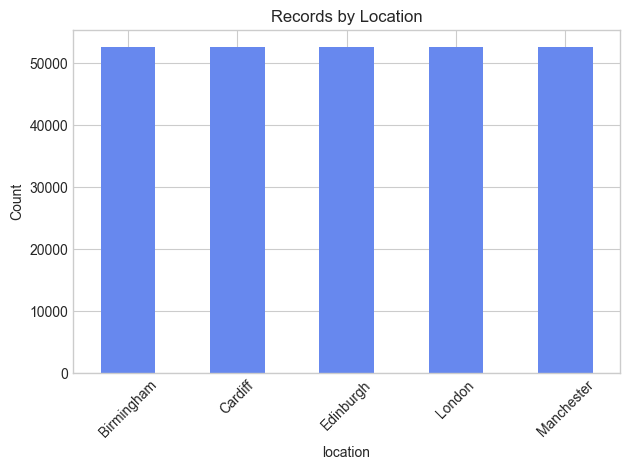

In [34]:
# How many locations?
print(f"Locations: {df['location'].nunique()}")
print(df['location'].value_counts())

# Records per location (should be roughly equal)
df.groupby('location').size().plot(kind='bar', title='Records by Location')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [35]:
# Records by year
print("Records by Year:")
print(df.groupby('year').size())

# Records by month
print("\nRecords by Month:")
print(df.groupby('month_name').size())

# Records by day of week
print("\nRecords by Day of Week:")
print(df.groupby('day_of_week').size())

Records by Year:
year
2020    43920
2021    43800
2022    43800
2023    43800
2024    43920
2025    43800
2026      120
dtype: int64

Records by Month:
month_name
April        21600
August       22320
December     22320
February     20400
January      22440
July         22320
June         21600
March        22320
May          22320
November     21600
October      22320
September    21600
dtype: int64

Records by Day of Week:
day_of_week
Friday       37560
Monday       37560
Saturday     37560
Sunday       37560
Thursday     37680
Tuesday      37560
Wednesday    37680
dtype: int64


In [36]:
# Temperature stats by location
df.groupby('location')['temperature_2m'].agg([
    'count', 'mean', 'std', 'min', 'max'
]).round(2)

,count,mean,std,min,max
location,,,,,
Birmingham,52632,10.43,5.90,-5.2,37.4
Cardiff,52632,11.41,5.50,-5.5,33.1
Edinburgh,52632,9.81,5.07,-6.7,29.4
London,52632,11.68,6.23,-10.3,37.9
Manchester,52632,10.71,5.67,-7.8,36.0


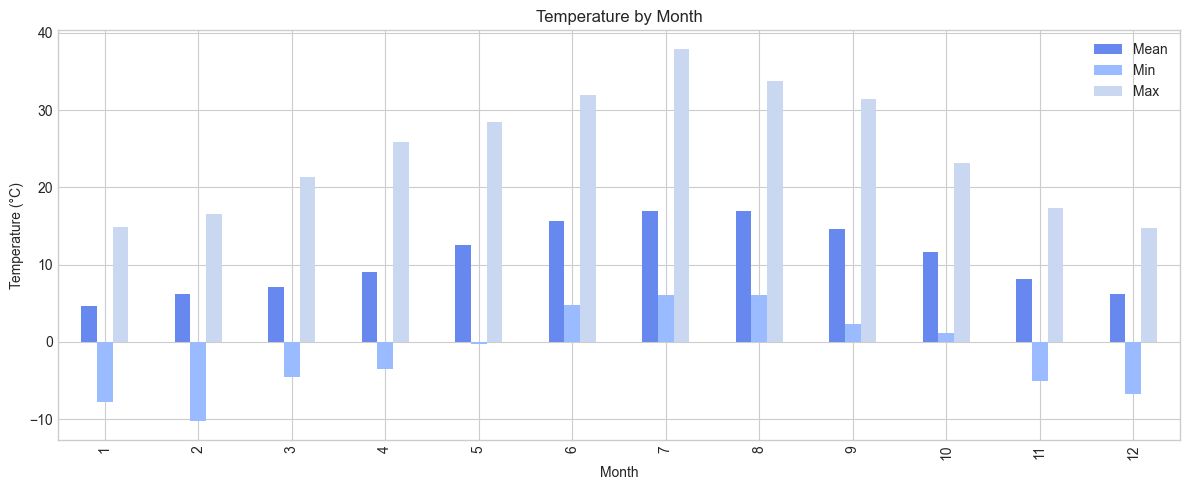

In [37]:
# Temperature by month (seasonal pattern)
monthly_stats = df.groupby('month')['temperature_2m'].agg(['mean', 'min', 'max']).round(2)
monthly_stats.plot(kind='bar', figsize=(12, 5), title='Temperature by Month')
plt.ylabel('Temperature (°C)')
plt.xlabel('Month')
plt.legend(['Mean', 'Min', 'Max'])
plt.tight_layout()
plt.show()

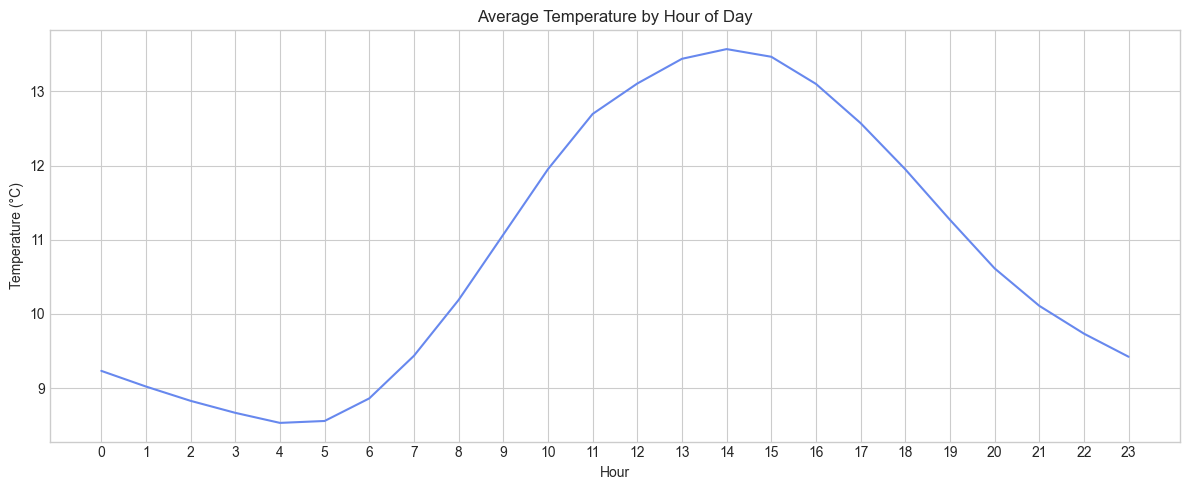

In [38]:
# Temperature by hour (daily pattern)
hourly_stats = df.groupby('hour')['temperature_2m'].mean()
hourly_stats.plot(kind='line', figsize=(12, 5), title='Average Temperature by Hour of Day')
plt.ylabel('Temperature (°C)')
plt.xlabel('Hour')
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()

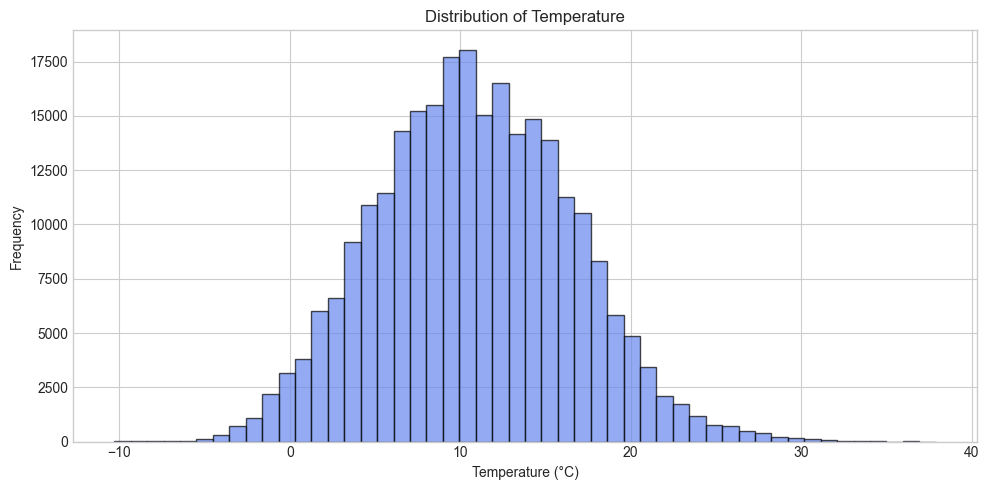

In [39]:
# Histogram
plt.figure(figsize=(10, 5))
df['temperature_2m'].hist(bins=50, edgecolor='black', alpha=0.7)
plt.title('Distribution of Temperature')
plt.xlabel('Temperature (°C)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

<Figure size 1200x600 with 0 Axes>

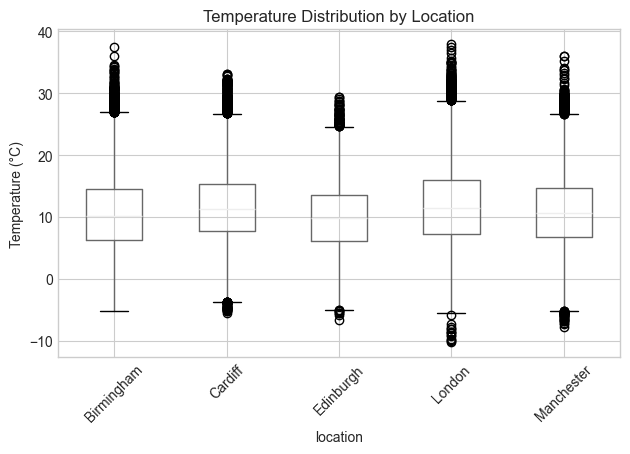

In [40]:
# Box plot by location
plt.figure(figsize=(12, 6))
df.boxplot(column='temperature_2m', by='location')
plt.title('Temperature Distribution by Location')
plt.suptitle('')  # Remove auto-title
plt.ylabel('Temperature (°C)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

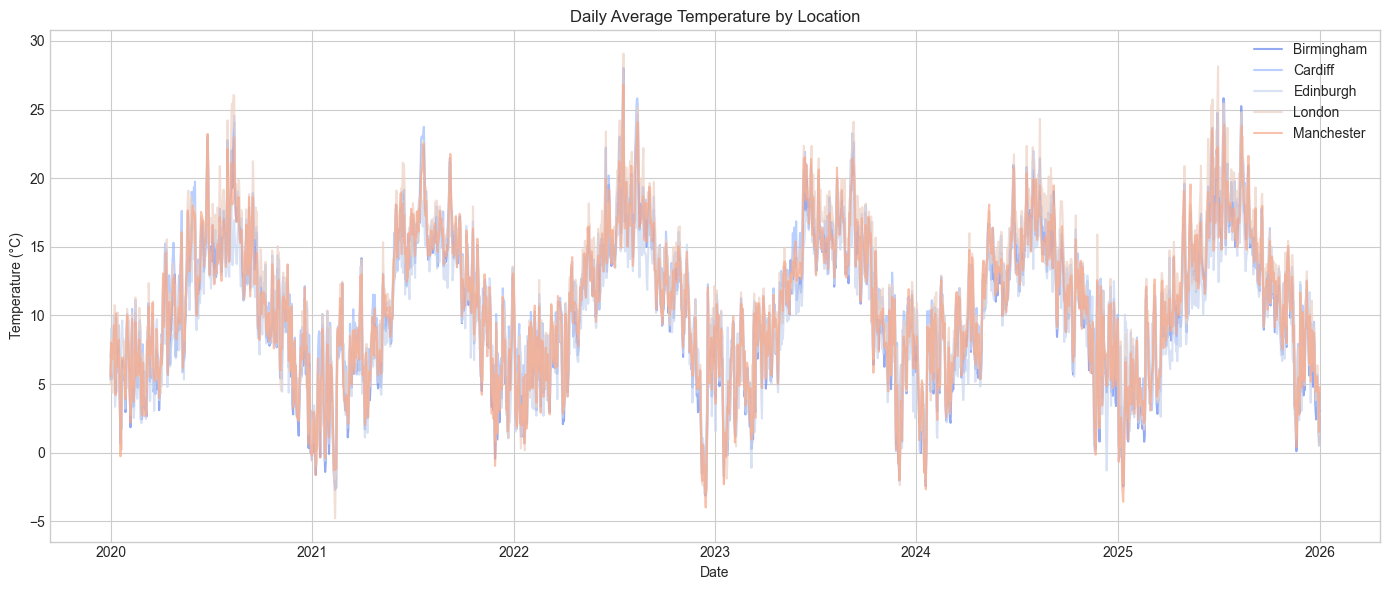

In [41]:
# Daily average temperature over time
daily_temp = df.groupby(['date', 'location'])['temperature_2m'].mean().reset_index()

plt.figure(figsize=(14, 6))
for location in daily_temp['location'].unique():
    loc_data = daily_temp[daily_temp['location'] == location]
    plt.plot(loc_data['date'], loc_data['temperature_2m'], label=location, alpha=0.7)

plt.title('Daily Average Temperature by Location')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.legend()
plt.tight_layout()
plt.show()

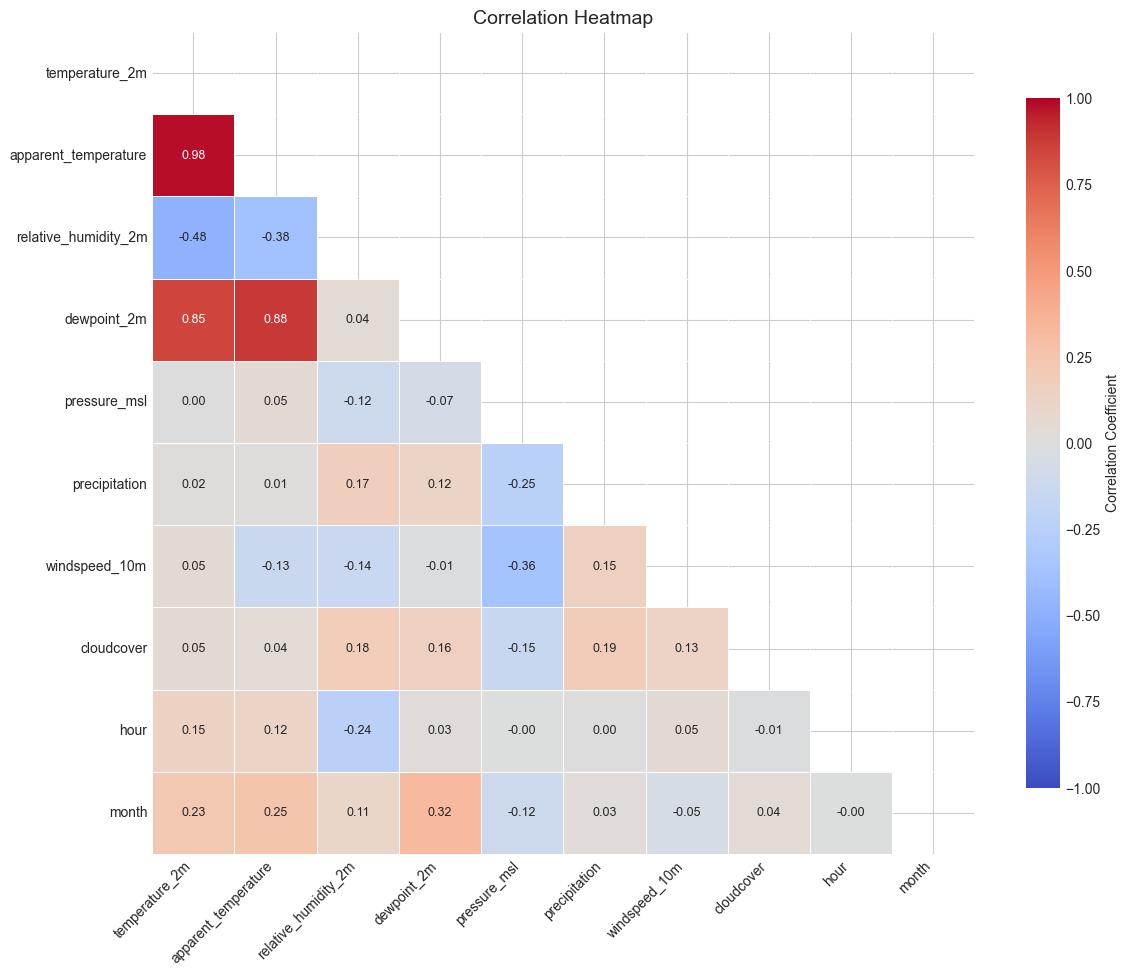

In [42]:
# Select key columns
key_cols = [
    'temperature_2m',
    'apparent_temperature',
    'relative_humidity_2m',
    'dewpoint_2m',
    'pressure_msl',
    'precipitation',
    'windspeed_10m',
    'cloudcover',
    'hour',
    'month',
]

key_cols = [c for c in key_cols if c in df.columns]
correlation_matrix = df[key_cols].corr()

# Plot
plt.figure(figsize=(12, 10))
mask = np.triu(correlation_matrix)

sns.heatmap(
    correlation_matrix,
    annot=True,
    annot_kws={'size': 9},
    mask=mask,
    cmap='coolwarm',
    vmin=-1, vmax=1,
    center=0,
    square=True,
    linewidths=.5,
    fmt='.2f',
    cbar_kws={'shrink': .8, 'label': 'Correlation Coefficient'}
)

plt.title('Correlation Heatmap', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [43]:
## 8. Visualisations
# ### 8.1 Distribution of Numerical Variables

# Histograms for numerical columns
n_cols = min(len(num_cols), 6)  # Limit to 6
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(num_cols[:n_cols]):
    axes[i].hist(df[col].dropna(), bins=30, edgecolor='black', alpha=0.7)
    axes[i].set_title(f'{col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')

# Hide empty subplots
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

NameError: name 'num_cols' is not defined

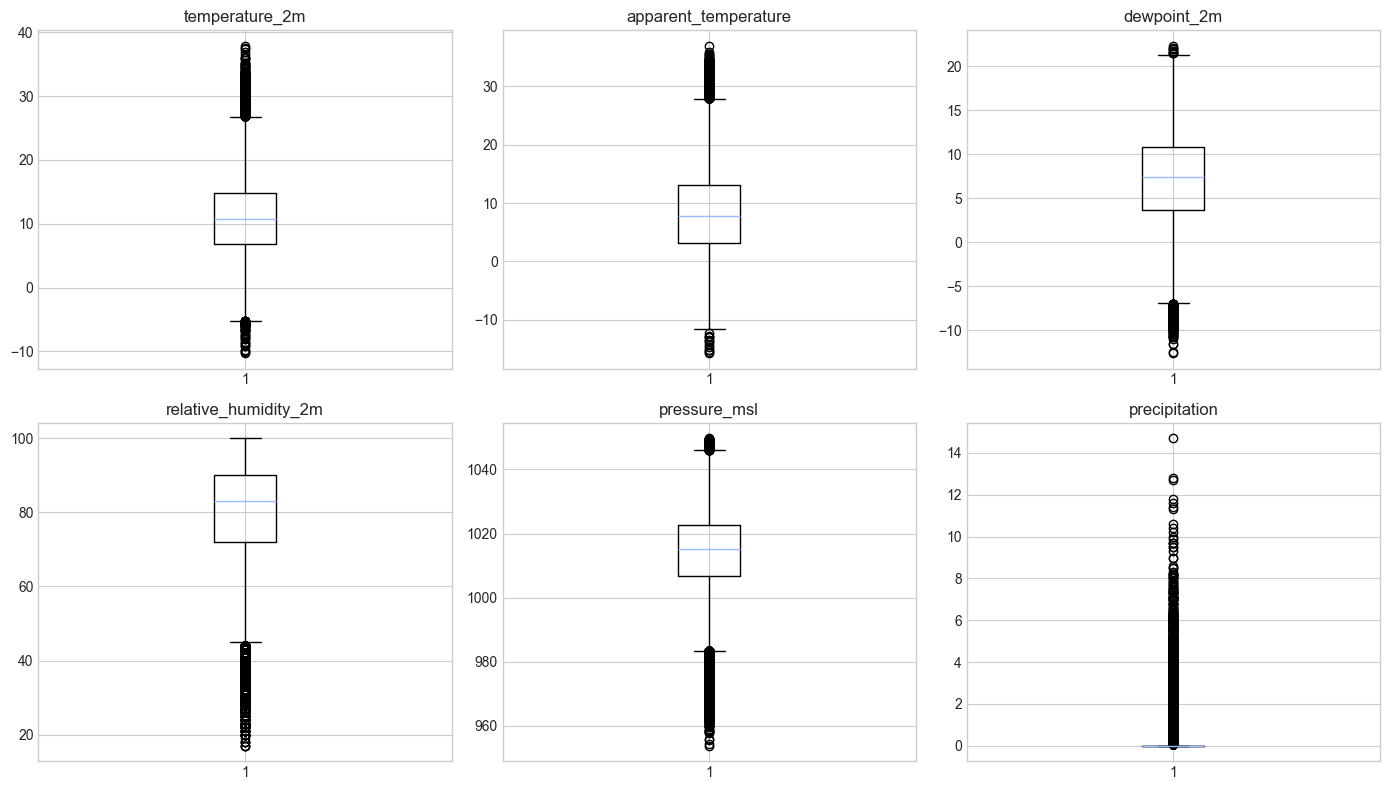

In [ ]:
# Box plots for numerical columns
n_cols = min(len(num_cols), 6)
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(num_cols[:n_cols]):
    axes[i].boxplot(df[col].dropna())
    axes[i].set_title(f'{col}')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

In [ ]:
# ### 8.4 Top Correlations (Sorted)

# %%
# Extract top correlations
def get_top_correlations(corr_matrix, n=20):
    """Extract top n correlations from correlation matrix."""
    pairs = []
    cols = corr_matrix.columns
    
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            pairs.append({
                'var_1': cols[i],
                'var_2': cols[j],
                'correlation': corr_matrix.iloc[i, j]
            })
    
    pairs_df = pd.DataFrame(pairs)
    pairs_df['abs_correlation'] = pairs_df['correlation'].abs()
    pairs_df = pairs_df.sort_values('abs_correlation', ascending=False)
    
    return pairs_df.head(n)

top_corr = get_top_correlations(correlation_matrix)
top_corr

,var_1,var_2,correlation,abs_correlation
35,max_temp_day,avg_temp_day,0.973017,0.973017
31,min_temp_day,avg_temp_day,0.951672,0.951672
5,temperature_2m,avg_temp_day,0.906994,0.906994
39,avg_temp_day,temp_7day_rolling_avg,0.891367,0.891367
4,temperature_2m,max_temp_day,0.882520,0.882520
30,min_temp_day,max_temp_day,0.871149,0.871149
36,max_temp_day,temp_7day_rolling_avg,0.870477,0.870477
3,temperature_2m,min_temp_day,0.863160,0.863160
32,min_temp_day,temp_7day_rolling_avg,0.851977,0.851977
6,temperature_2m,temp_7day_rolling_avg,0.809082,0.809082


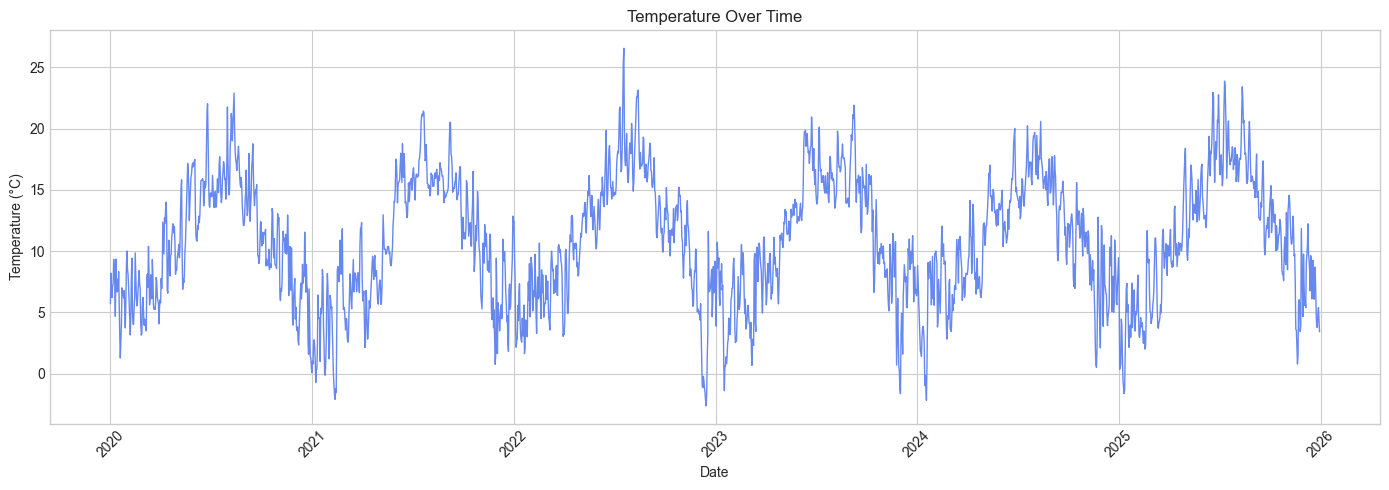

In [ ]:
# ### 8.5 Time Series (if applicable)

# %%
# Time series plot
if 'date' in df.columns and 'temperature_2m' in df.columns:
    # Aggregate by date
    daily = df.groupby('date')['temperature_2m'].mean().reset_index()
    
    plt.figure(figsize=(14, 5))
    plt.plot(daily['date'], daily['temperature_2m'], linewidth=1)
    plt.title('Temperature Over Time')
    plt.xlabel('Date')
    plt.ylabel('Temperature (°C)')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [ ]:
# ### 8.7 Grouped Analysis

# %%
# Average by category (e.g., location)
if 'location' in df.columns and 'temperature_2m' in df.columns:
    grouped = df.groupby('location')['temperature_2m'].agg(['mean', 'min', 'max', 'std'])
    grouped = grouped.round(2)
    print("Temperature by Location:")
    print(grouped)

Temperature by Location:
             mean   min   max   std
location                           
Birmingham  10.44  -5.2  37.4  5.90
Cardiff     11.42  -5.5  33.1  5.50
Edinburgh    9.82  -6.7  29.4  5.06
London      11.69 -10.3  37.9  6.23
Manchester  10.71  -7.8  36.0  5.66


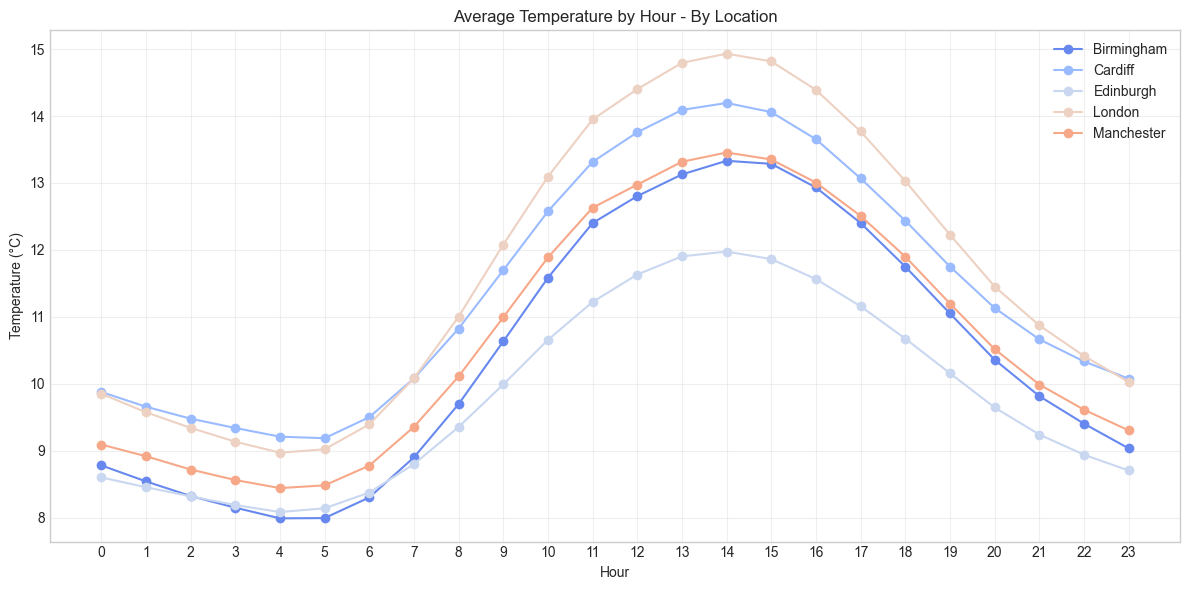

In [ ]:
plt.figure(figsize=(12, 6))
for location in df['location'].unique():
    loc_data = df[df['location'] == location]
    hourly_avg = loc_data.groupby('hour')['temperature_2m'].mean()
    plt.plot(hourly_avg.index, hourly_avg.values, marker='o', label=location)

plt.title('Average Temperature by Hour - By Location')
plt.xlabel('Hour')
plt.ylabel('Temperature (°C)')
plt.xticks(range(0, 24))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

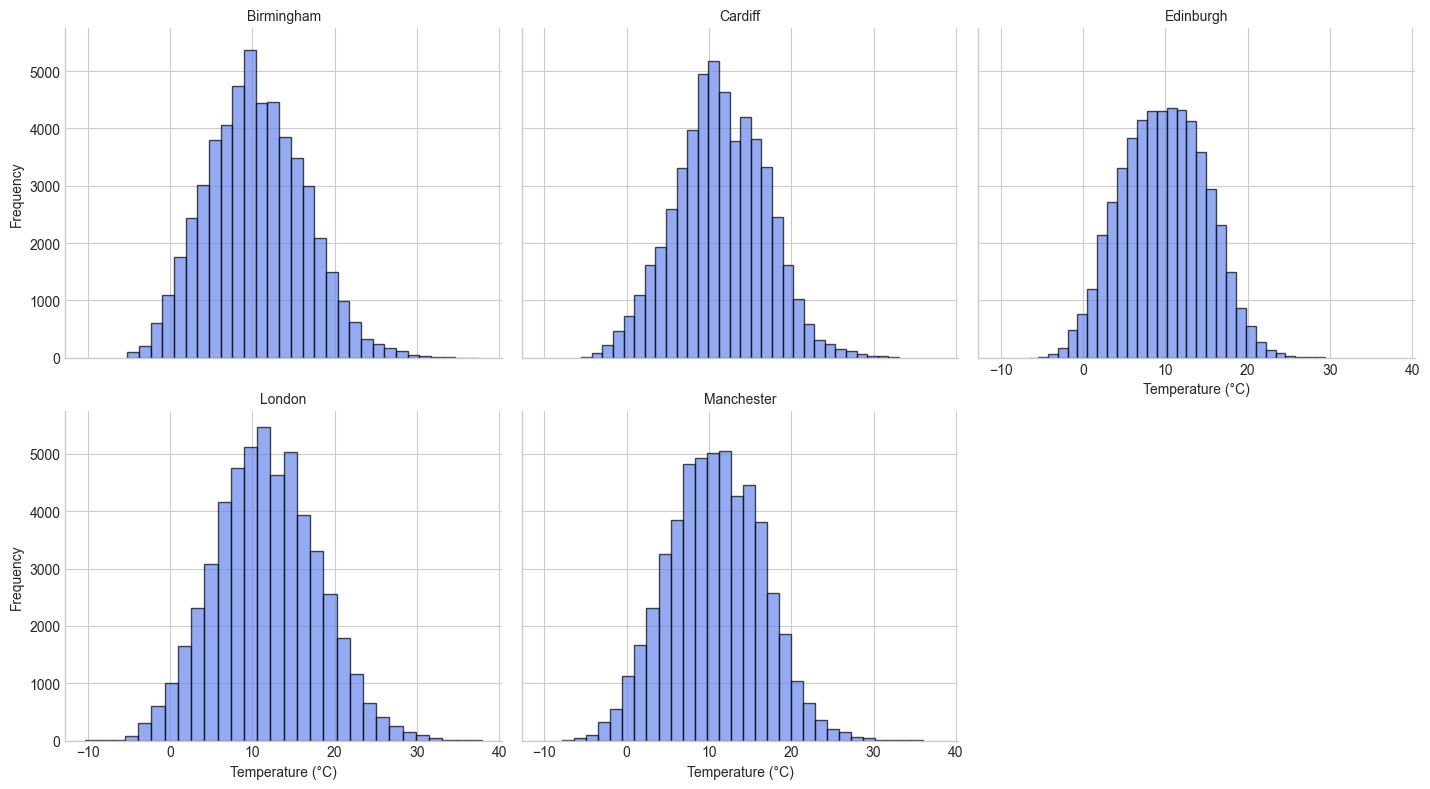

In [ ]:
# FacetGrid uses height and aspect instead of figsize
g = sns.FacetGrid(df, col='location', col_wrap=3, height=4, aspect=1.2)
g.map(plt.hist, 'temperature_2m', bins=30, edgecolor='black', alpha=0.7)
g.set_titles('{col_name}')
g.set_axis_labels('Temperature (°C)', 'Frequency')
plt.tight_layout()
plt.show()

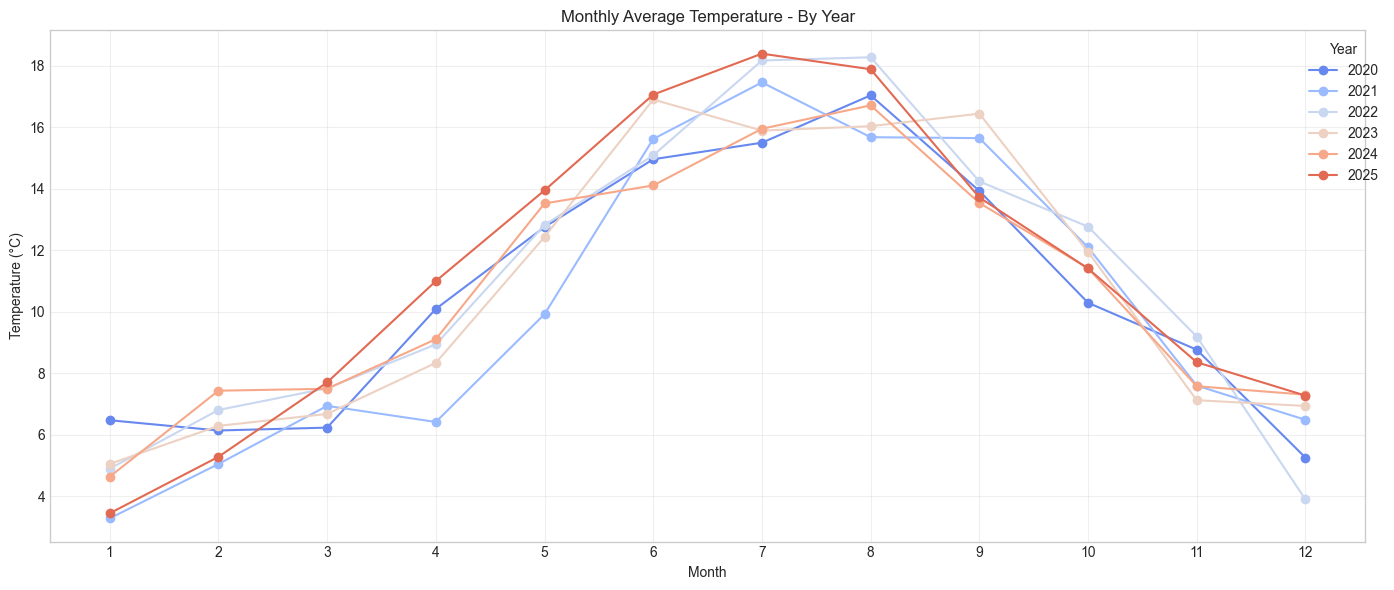

In [ ]:
plt.figure(figsize=(14, 6))
for year in sorted(df['year'].unique()):
    year_data = df[df['year'] == year]
    monthly_avg = year_data.groupby('month')['temperature_2m'].mean()
    plt.plot(monthly_avg.index, monthly_avg.values, marker='o', label=year)

plt.title('Monthly Average Temperature - By Year')
plt.xlabel('Month')
plt.ylabel('Temperature (°C)')
plt.xticks(range(1, 13))
plt.legend(title='Year', bbox_to_anchor=(1.02, 1))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

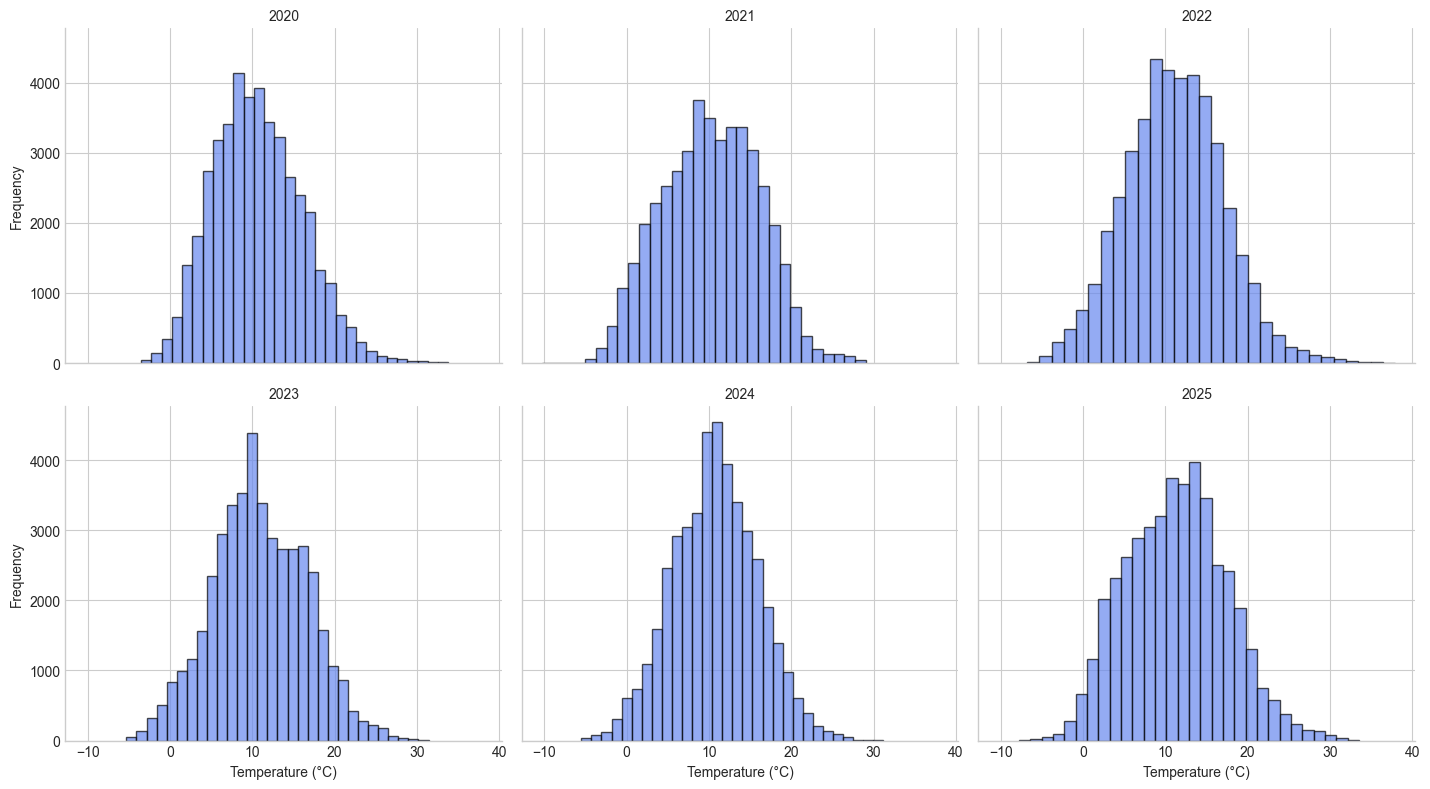

In [ ]:
# FacetGrid uses height and aspect instead of figsize
g = sns.FacetGrid(df, col='year', col_wrap=3, height=4, aspect=1.2)
g.map(plt.hist, 'temperature_2m', bins=30, edgecolor='black', alpha=0.7)
g.set_titles('{col_name}')
g.set_axis_labels('Temperature (°C)', 'Frequency')
plt.tight_layout()
plt.show()

<Figure size 1400x600 with 0 Axes>

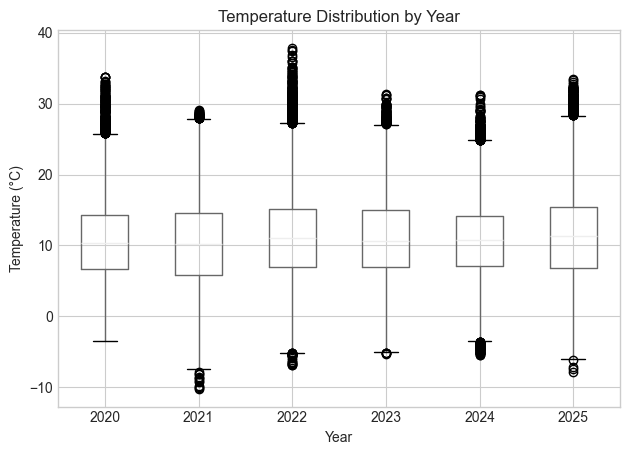

In [ ]:
plt.figure(figsize=(14, 6))
df.boxplot(column='temperature_2m', by='year')
plt.title('Temperature Distribution by Year')
plt.suptitle('')
plt.xlabel('Year')
plt.ylabel('Temperature (°C)')
plt.tight_layout()
plt.show()

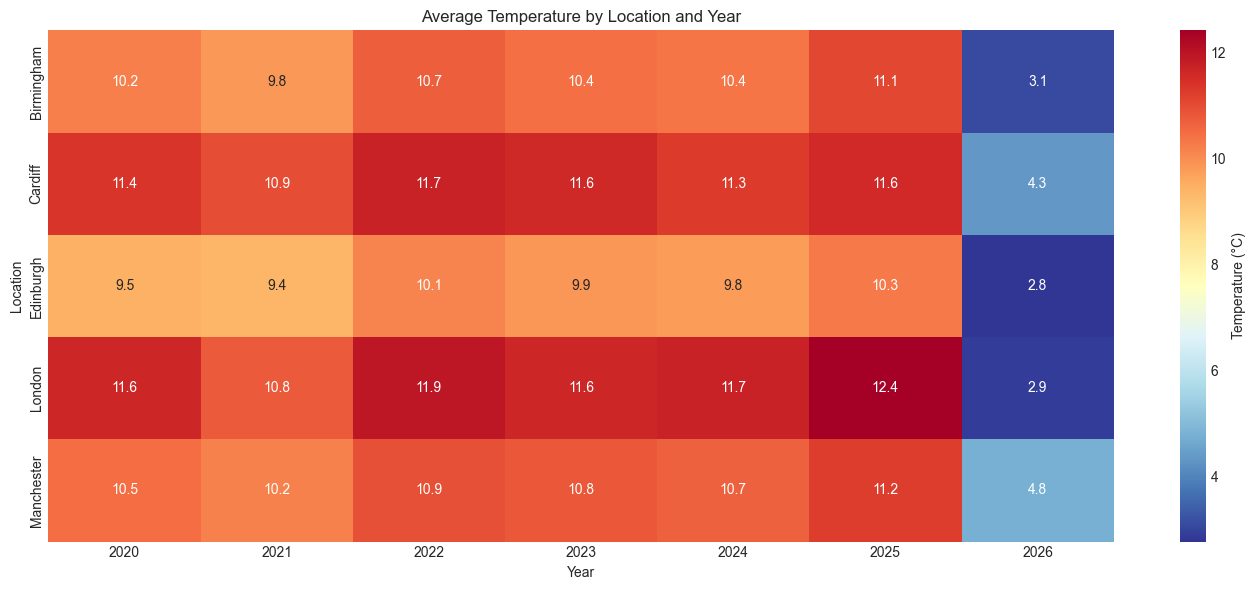

In [ ]:
# Pivot table
pivot = df.groupby(['location', 'year'])['temperature_2m'].mean().reset_index()
pivot_table = pivot.pivot(index='location', columns='year', values='temperature_2m')

# Plot
plt.figure(figsize=(14, 6))
sns.heatmap(
    pivot_table,
    annot=True,
    fmt='.1f',
    cmap='RdYlBu_r',
    cbar_kws={'label': 'Temperature (°C)'}
)
plt.title('Average Temperature by Location and Year')
plt.xlabel('Year')
plt.ylabel('Location')
plt.tight_layout()
plt.show()

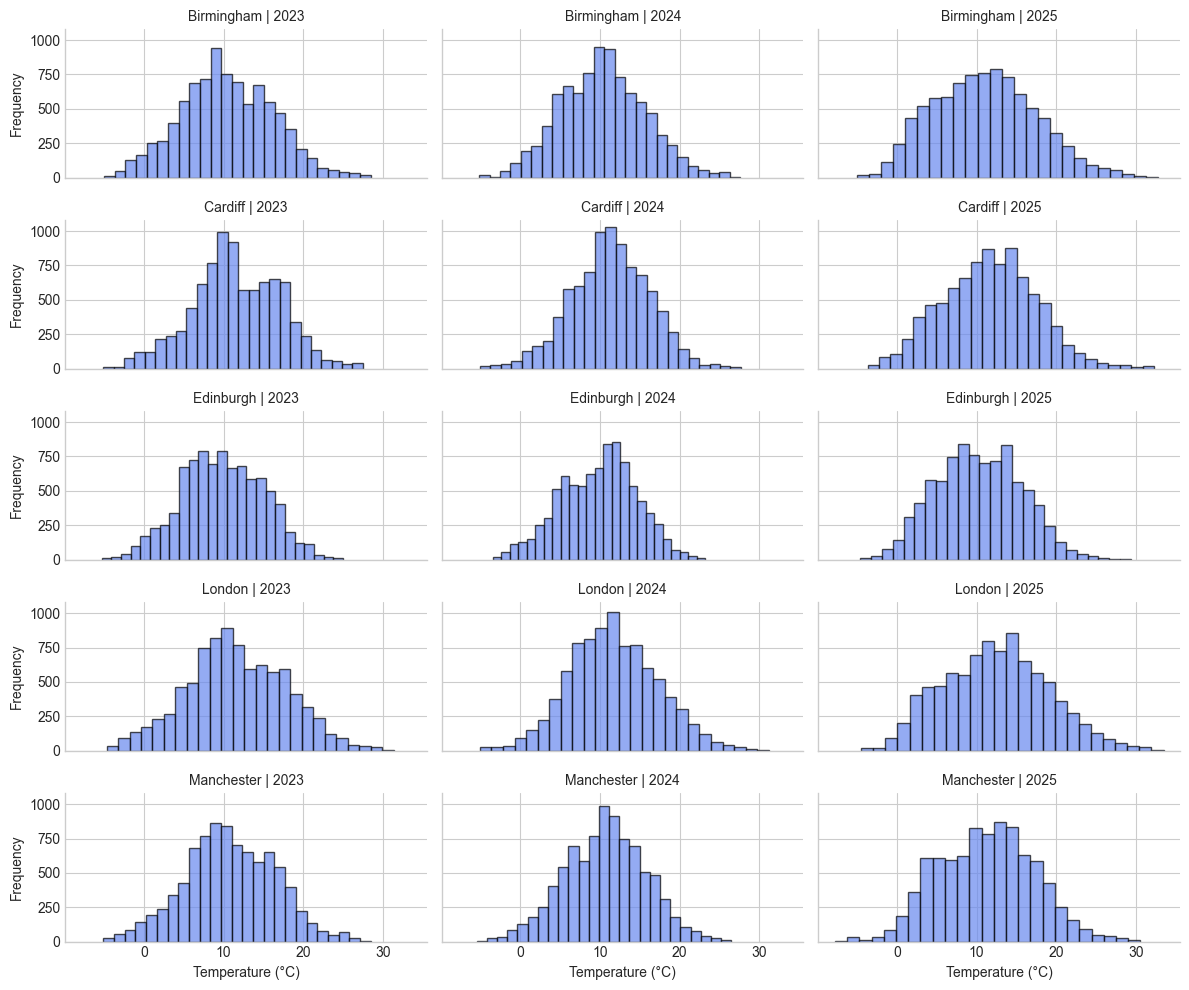

In [ ]:
# Filter to last 3 years to fit on screen
recent_years = sorted(df['year'].unique())[-3:]
df_recent = df[df['year'].isin(recent_years)]

# FacetGrid uses height and aspect instead of figsize.
# Compute sensible height/aspect to approximate figsize=(14, 12)
n_rows = df_recent['location'].nunique()
n_cols = df_recent['year'].nunique()
height = (10 / n_rows) if n_rows > 0 else 3
aspect = ((12 / n_cols) / height) if n_cols > 0 else 1.5

g = sns.FacetGrid(df_recent, row='location', col='year', height=height, aspect=aspect)
g.map(plt.hist, 'temperature_2m', bins=25, edgecolor='black', alpha=0.7)
g.set_titles('{row_name} | {col_name}')
g.set_axis_labels('Temperature (°C)', 'Frequency')
plt.tight_layout()
plt.show()

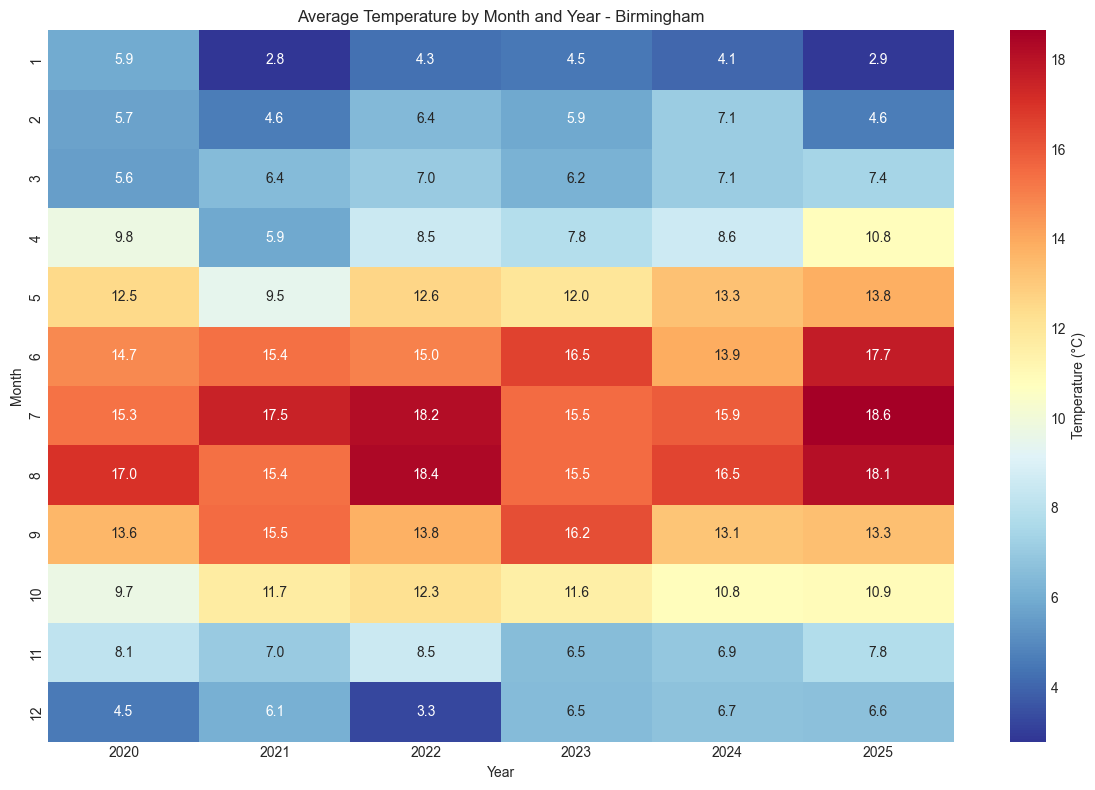

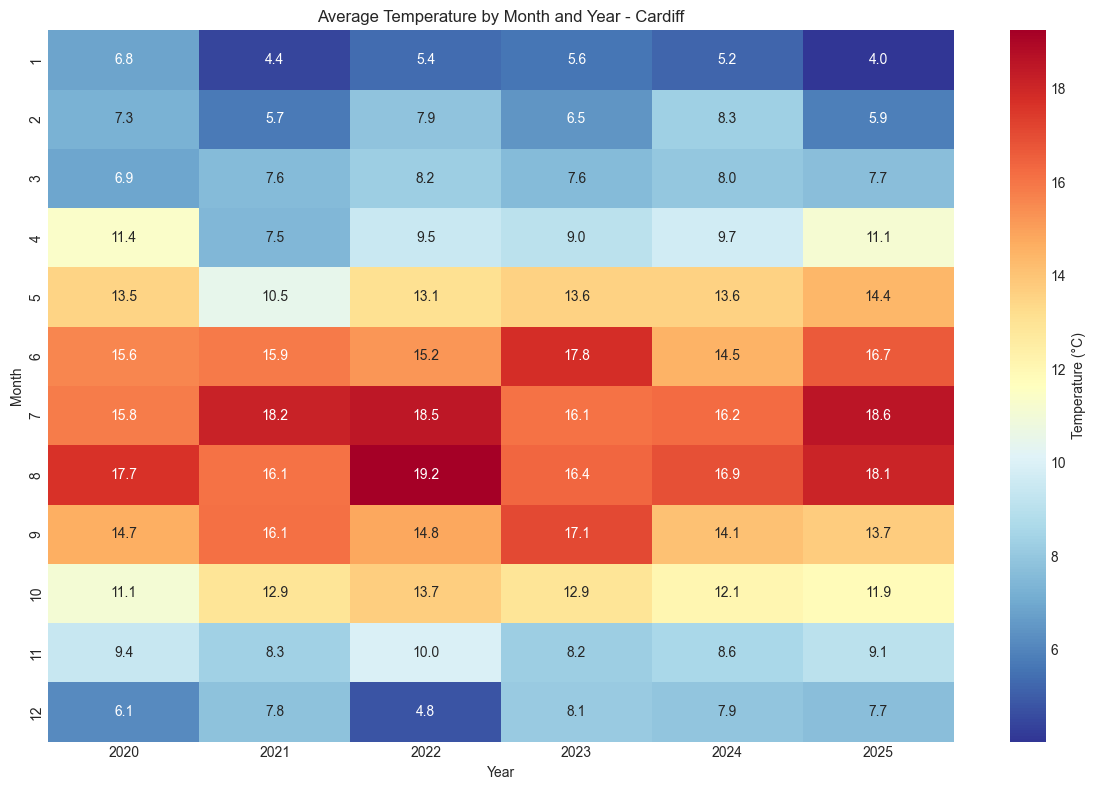

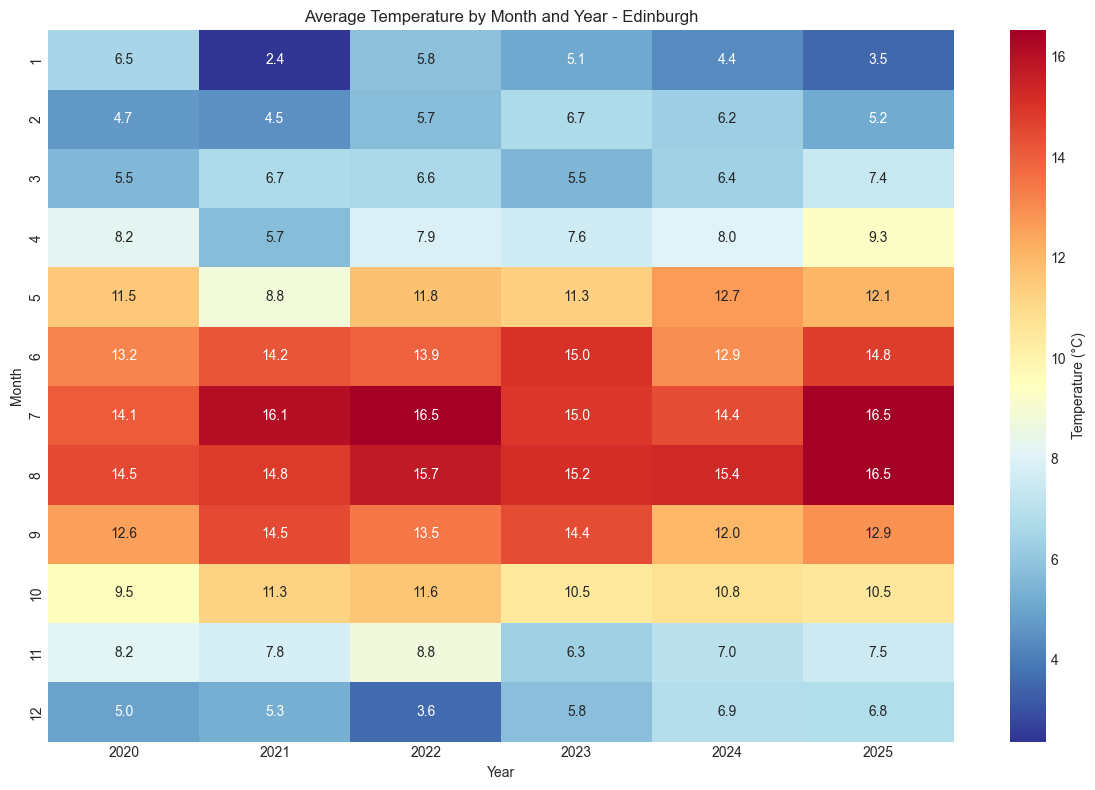

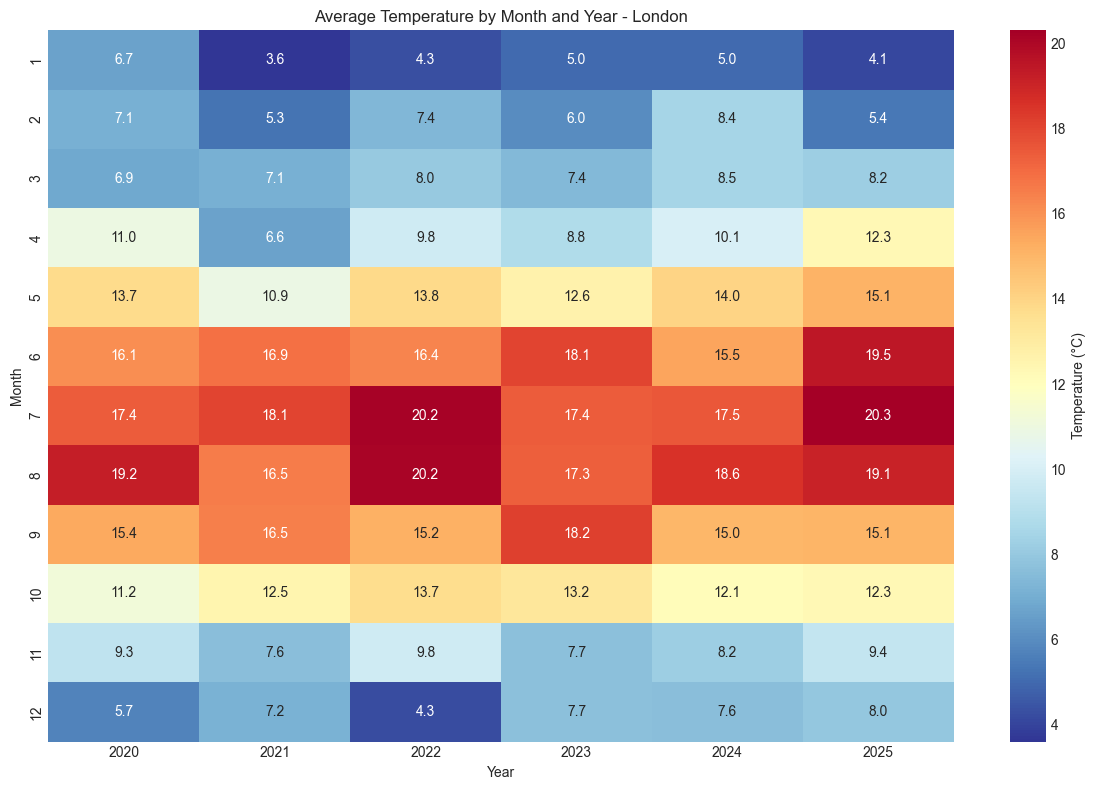

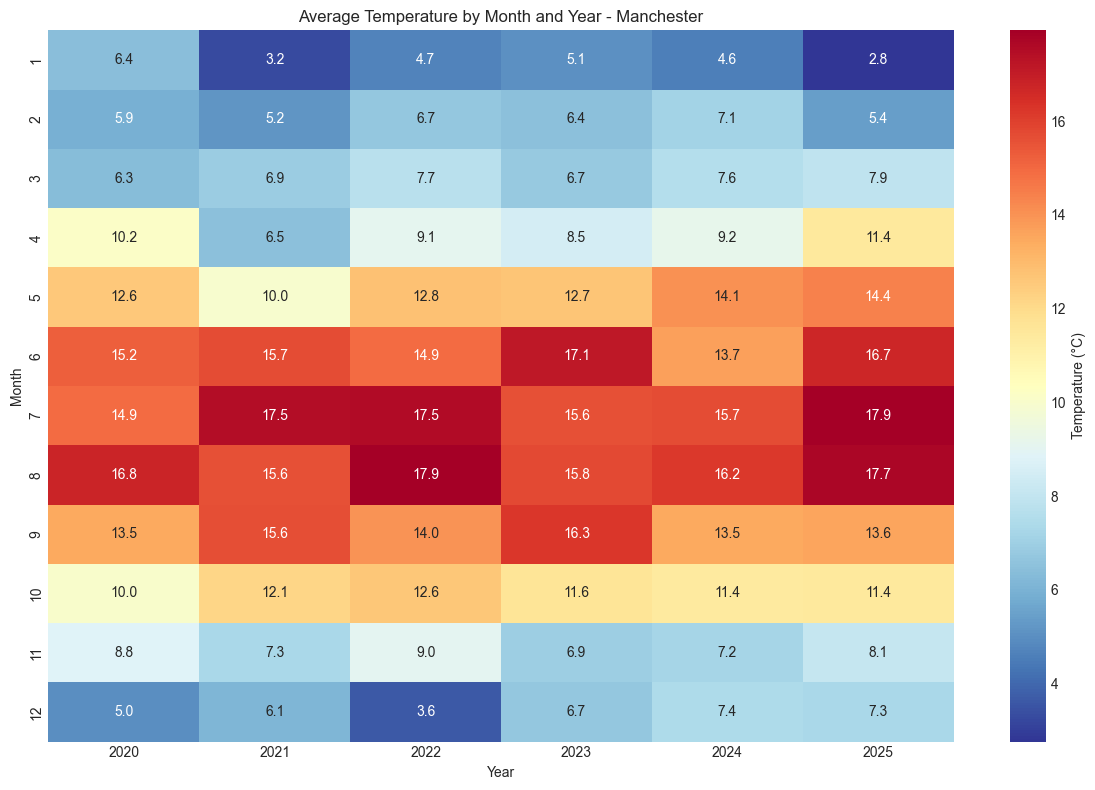

In [ ]:
# Create a heatmap for each location
for location in df['location'].unique():
    loc_data = df[df['location'] == location]
    
    # Pivot: Month (rows) × Year (columns)
    pivot = loc_data.groupby(['month', 'year'])['temperature_2m'].mean().reset_index()
    pivot_table = pivot.pivot(index='month', columns='year', values='temperature_2m')
    
    # Plot
    plt.figure(figsize=(12, 8))
    sns.heatmap(
        pivot_table,
        annot=True,
        fmt='.1f',
        cmap='RdYlBu_r',
        cbar_kws={'label': 'Temperature (°C)'}
    )
    plt.title(f'Average Temperature by Month and Year - {location}')
    plt.xlabel('Year')
    plt.ylabel('Month')
    plt.tight_layout()
    plt.show()

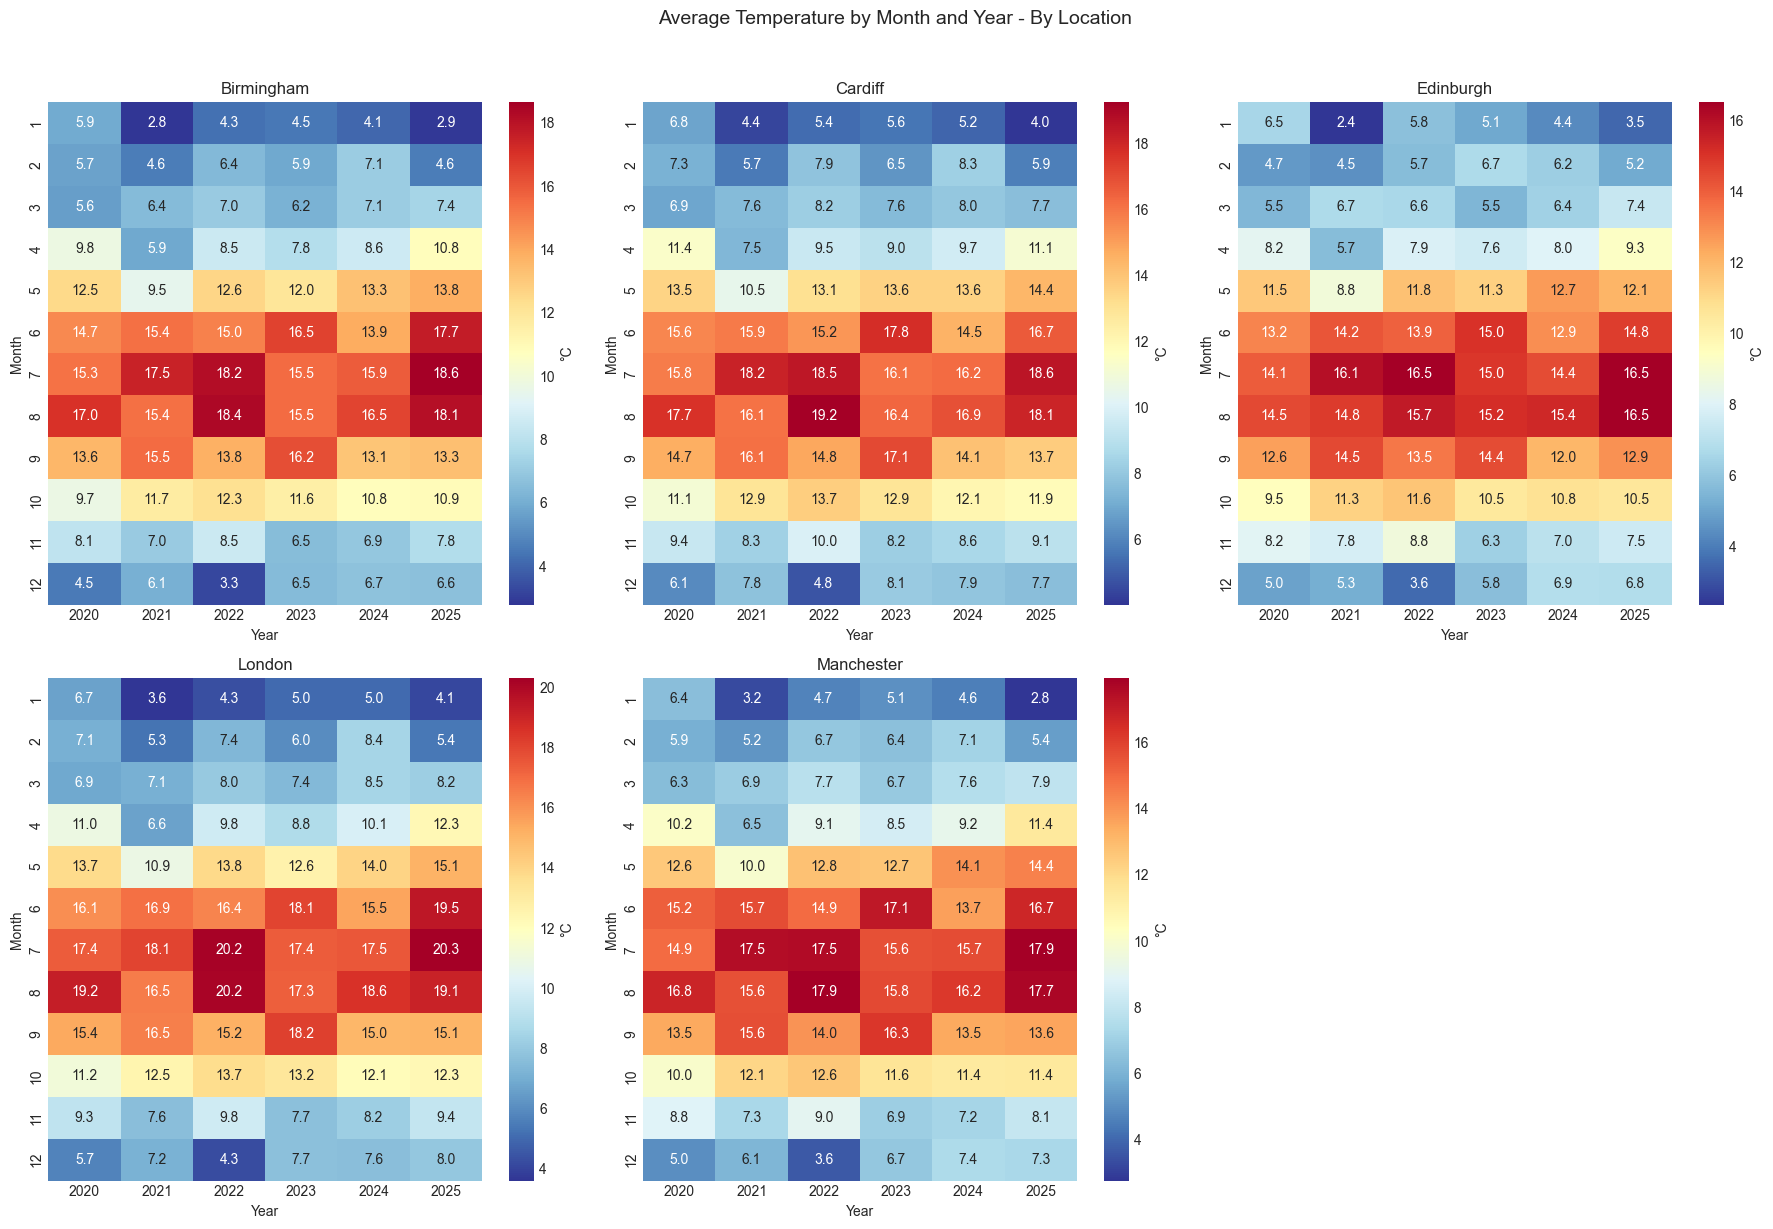

In [ ]:
locations = df['location'].unique()
n_locations = len(locations)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for i, location in enumerate(locations):
    loc_data = df[df['location'] == location]
    
    # Pivot: Month (rows) × Year (columns)
    pivot = loc_data.groupby(['month', 'year'])['temperature_2m'].mean().reset_index()
    pivot_table = pivot.pivot(index='month', columns='year', values='temperature_2m')
    
    # Plot
    sns.heatmap(
        pivot_table,
        annot=True,
        fmt='.1f',
        cmap='RdYlBu_r',
        ax=axes[i],
        cbar_kws={'label': '°C'}
    )
    axes[i].set_title(f'{location}')
    axes[i].set_xlabel('Year')
    axes[i].set_ylabel('Month')

# Hide empty subplots if less than 6 locations
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Average Temperature by Month and Year - By Location', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

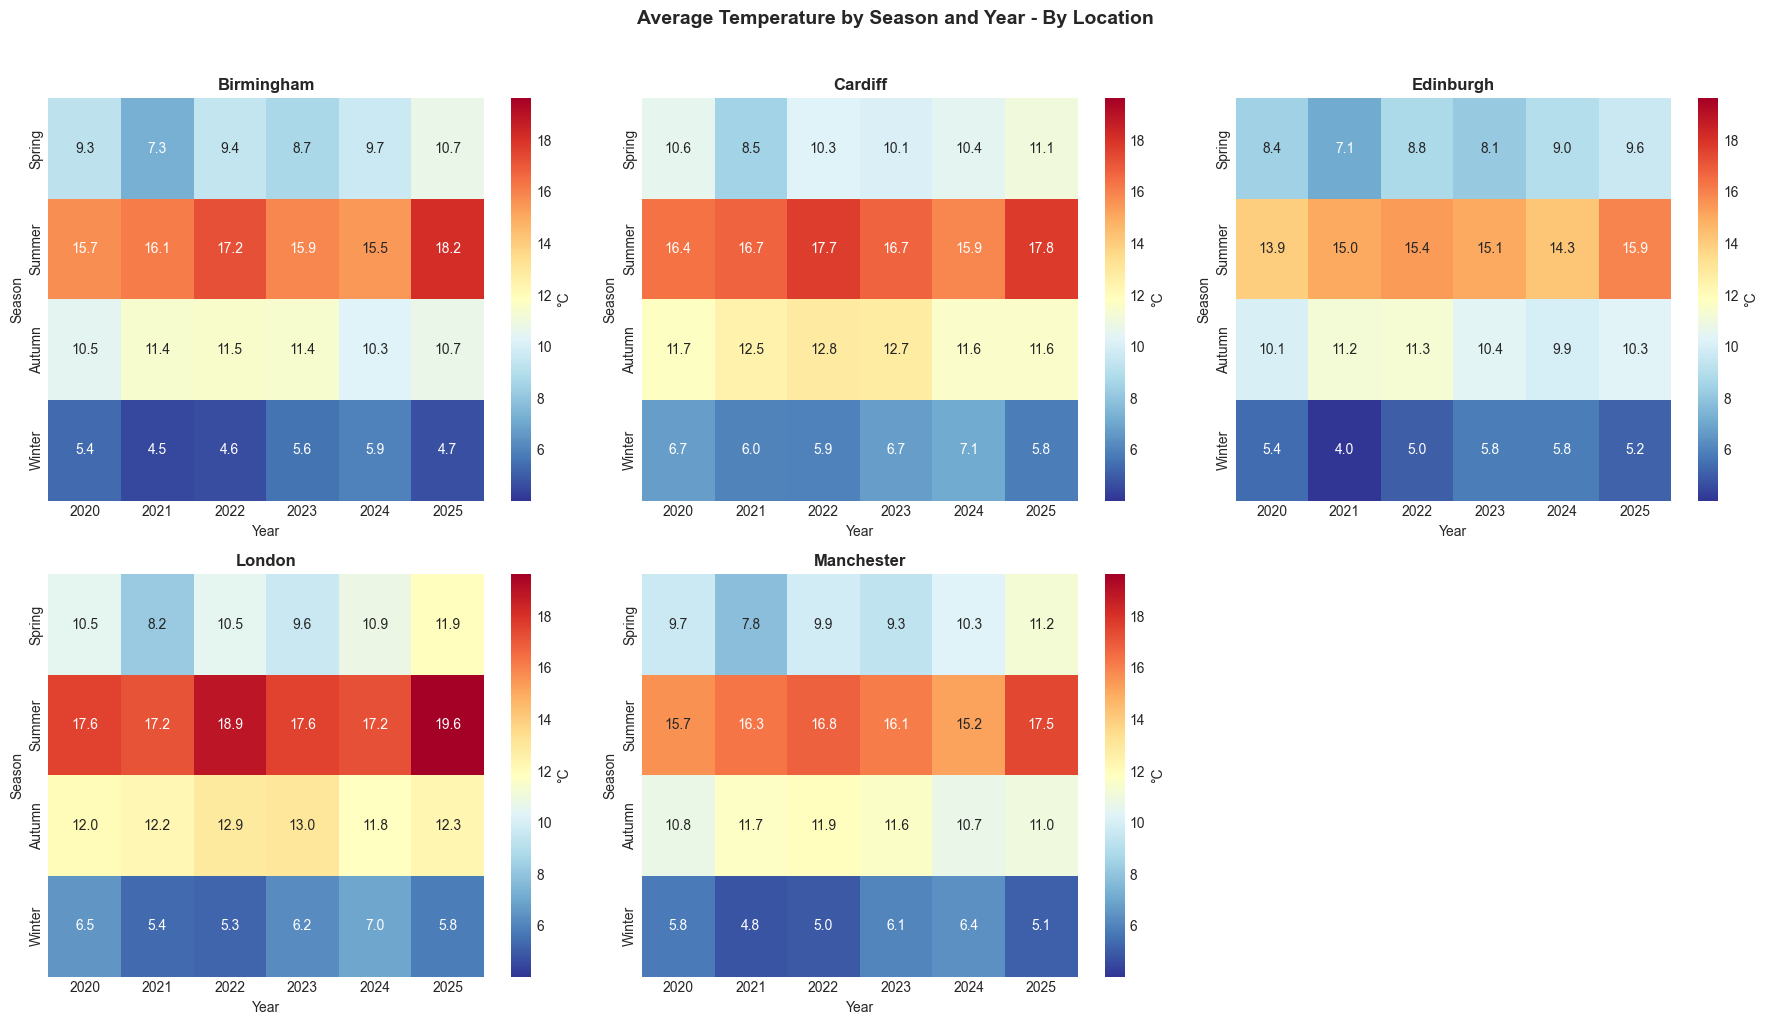

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Define seasons
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Autumn'

df['season'] = df['month'].apply(get_season)

# Season order
season_order = ['Spring', 'Summer', 'Autumn', 'Winter']

locations = df['location'].unique()
n_locations = len(locations)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, location in enumerate(locations):
    loc_data = df[df['location'] == location]
    
    # Pivot: Season (rows) × Year (columns)
    pivot = loc_data.groupby(['season', 'year'])['temperature_2m'].mean().reset_index()
    pivot_table = pivot.pivot(index='season', columns='year', values='temperature_2m')
    
    # Reorder seasons
    pivot_table = pivot_table.reindex(season_order)
    
    # Plot
    sns.heatmap(
        pivot_table,
        annot=True,
        fmt='.1f',
        cmap='RdYlBu_r',
        ax=axes[i],
        cbar_kws={'label': '°C'},
        vmin=df.groupby(['season', 'year', 'location'])['temperature_2m'].mean().min(),
        vmax=df.groupby(['season', 'year', 'location'])['temperature_2m'].mean().max()
    )
    axes[i].set_title(f'{location}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Year')
    axes[i].set_ylabel('Season')

# Hide empty subplots if less than 6 locations
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Average Temperature by Season and Year - By Location', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

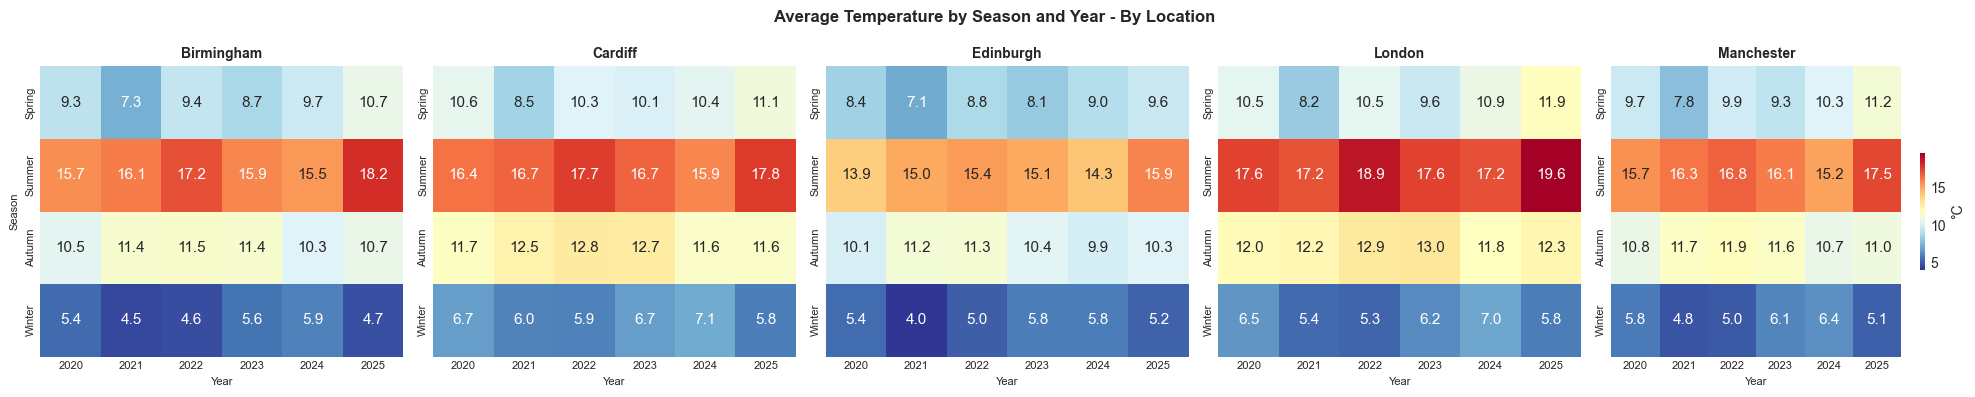

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Define seasons
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Autumn'

df['season'] = df['month'].apply(get_season)

# Season order
season_order = ['Spring', 'Summer', 'Autumn', 'Winter']

locations = df['location'].unique()
n_locations = len(locations)

# One row, smaller figure
fig, axes = plt.subplots(1, n_locations, figsize=(20, 4))

# Get global min/max for consistent colour scale
vmin = df.groupby(['season', 'year', 'location'])['temperature_2m'].mean().min()
vmax = df.groupby(['season', 'year', 'location'])['temperature_2m'].mean().max()

for i, location in enumerate(locations):
    loc_data = df[df['location'] == location]
    
    # Pivot: Season (rows) × Year (columns)
    pivot = loc_data.groupby(['season', 'year'])['temperature_2m'].mean().reset_index()
    pivot_table = pivot.pivot(index='season', columns='year', values='temperature_2m')
    
    # Reorder seasons
    pivot_table = pivot_table.reindex(season_order)
    
    # Plot - only show colorbar on last subplot
    sns.heatmap(
        pivot_table,
        annot=True,
        fmt='.1f',
        annot_kws={'size': 11},
        cmap='RdYlBu_r',
        ax=axes[i],
        cbar=(i == n_locations - 1),
        cbar_kws={'label': '°C', 'shrink': 0.4},
        vmin=vmin,
        vmax=vmax
    )
    axes[i].set_title(f'{location}', fontsize=10, fontweight='bold')
    axes[i].set_xlabel('Year', fontsize=8)
    axes[i].set_ylabel('Season' if i == 0 else '', fontsize=8)
    axes[i].tick_params(axis='both', labelsize=8)

plt.suptitle('Average Temperature by Season and Year - By Location', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

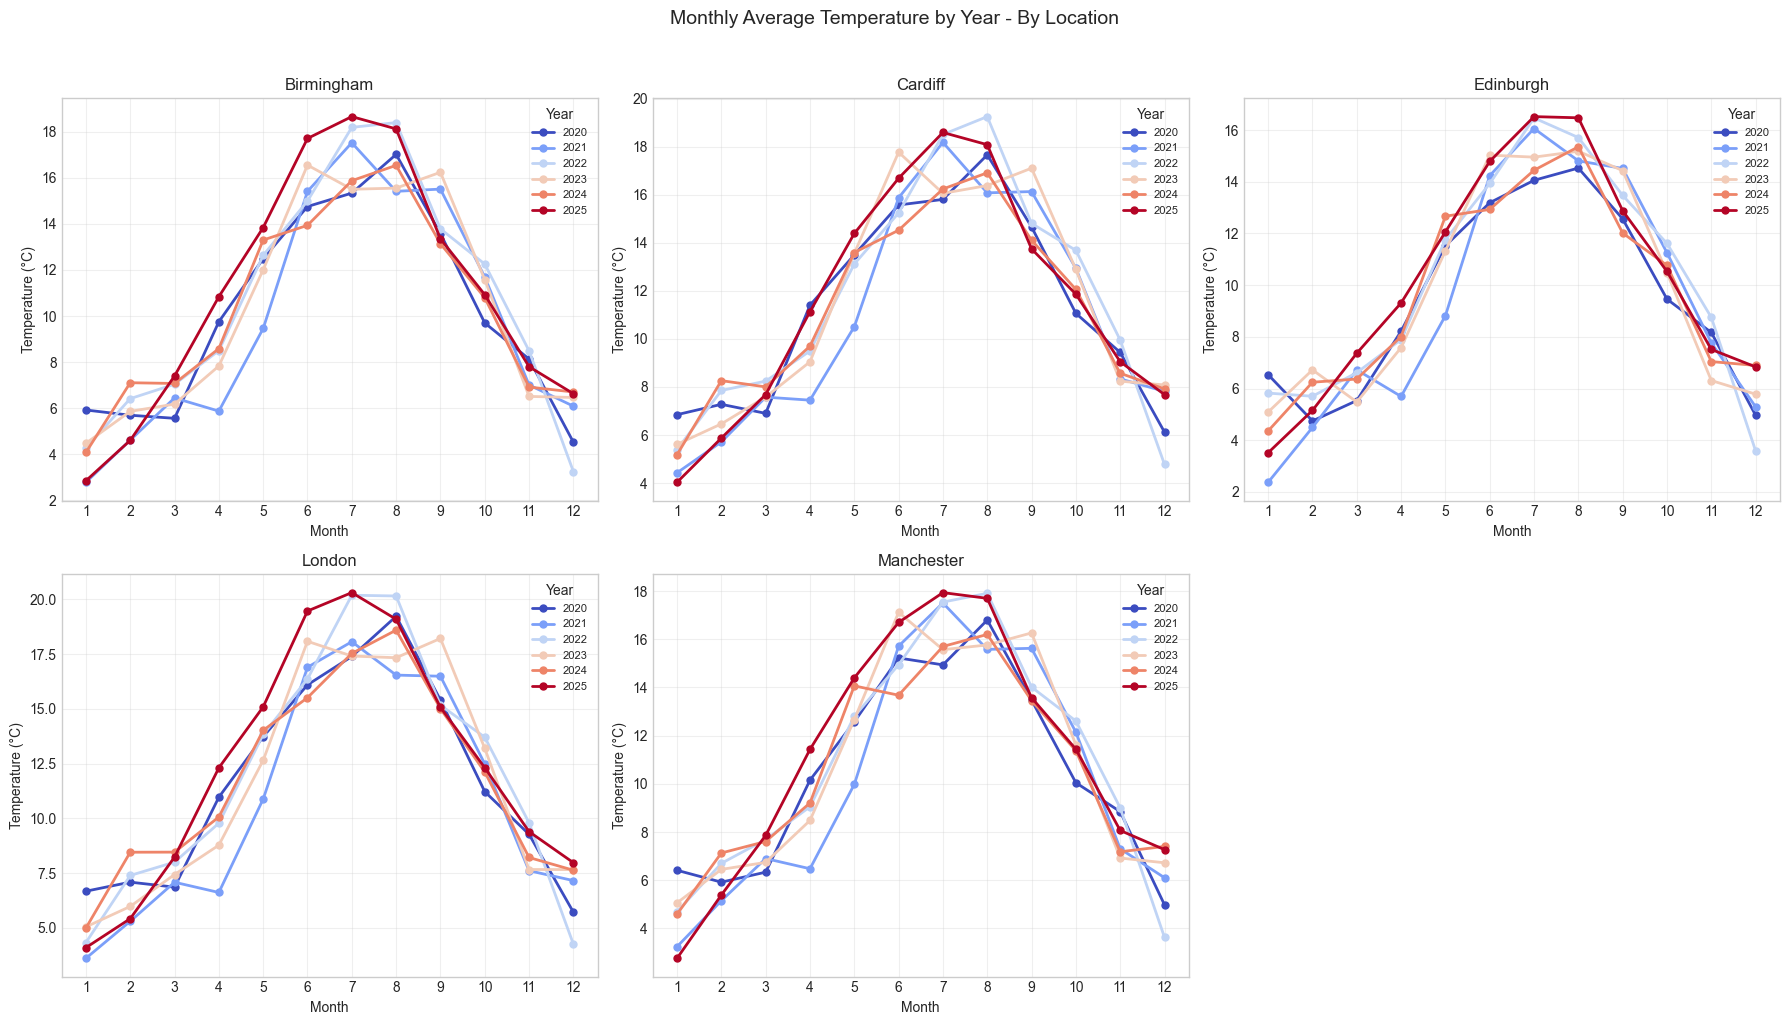

In [ ]:
locations = df['location'].unique()
n_locations = len(locations)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

# Color palette for years
years = sorted(df['year'].unique())
colors = plt.cm.coolwarm(np.linspace(0, 1, len(years)))

for i, location in enumerate(locations):
    loc_data = df[df['location'] == location]
    
    for j, year in enumerate(years):
        year_data = loc_data[loc_data['year'] == year]
        monthly_avg = year_data.groupby('month')['temperature_2m'].mean()
        axes[i].plot(
            monthly_avg.index, 
            monthly_avg.values, 
            marker='o', 
            label=year, 
            color=colors[j],
            linewidth=2,
            markersize=5
        )
    
    axes[i].set_title(f'{location}')
    axes[i].set_xlabel('Month')
    axes[i].set_ylabel('Temperature (°C)')
    axes[i].set_xticks(range(1, 13))
    axes[i].grid(True, alpha=0.3)
    axes[i].legend(title='Year', fontsize=8)

# Hide empty subplots
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Monthly Average Temperature by Year - By Location', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

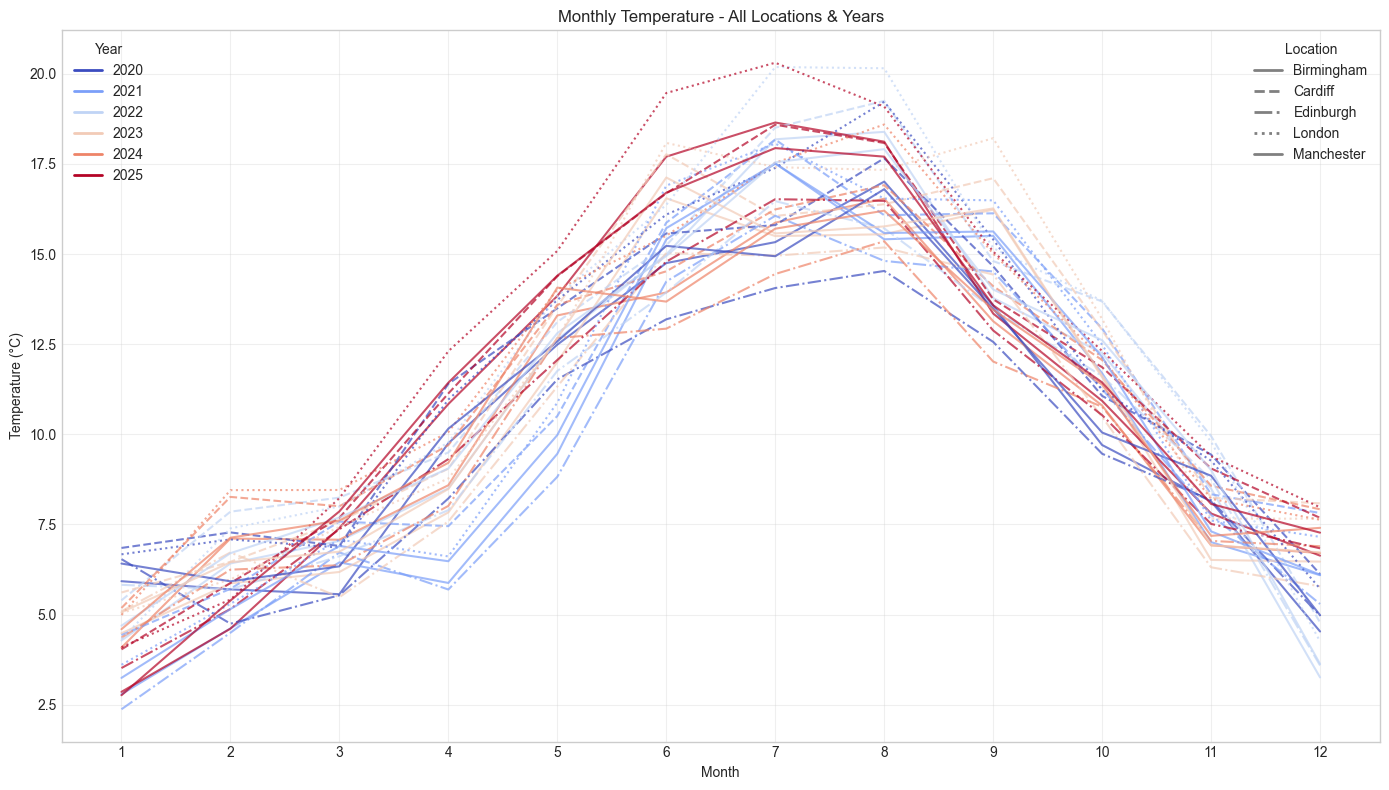

In [ ]:
plt.figure(figsize=(14, 8))

# Create unique line for each location-year combination
locations = df['location'].unique()
years = sorted(df['year'].unique())

# Color by year, line style by location
colors = plt.cm.coolwarm(np.linspace(0, 1, len(years)))
line_styles = ['-', '--', '-.', ':', '-', '--']

for i, location in enumerate(locations):
    for j, year in enumerate(years):
        data = df[(df['location'] == location) & (df['year'] == year)]
        monthly_avg = data.groupby('month')['temperature_2m'].mean()
        
        plt.plot(
            monthly_avg.index,
            monthly_avg.values,
            color=colors[j],
            linestyle=line_styles[i % len(line_styles)],
            linewidth=1.5,
            alpha=0.7,
            label=f'{location} {year}' if i == 0 else ''  # Only label once per year
        )

plt.title('Monthly Temperature - All Locations & Years')
plt.xlabel('Month')
plt.ylabel('Temperature (°C)')
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)

# Custom legend
from matplotlib.lines import Line2D
year_handles = [Line2D([0], [0], color=colors[j], linewidth=2, label=year) for j, year in enumerate(years)]
loc_handles = [Line2D([0], [0], color='gray', linestyle=line_styles[i], linewidth=2, label=loc) for i, loc in enumerate(locations)]

legend1 = plt.legend(handles=year_handles, title='Year', loc='upper left')
plt.gca().add_artist(legend1)
plt.legend(handles=loc_handles, title='Location', loc='upper right')

plt.tight_layout()
plt.show()

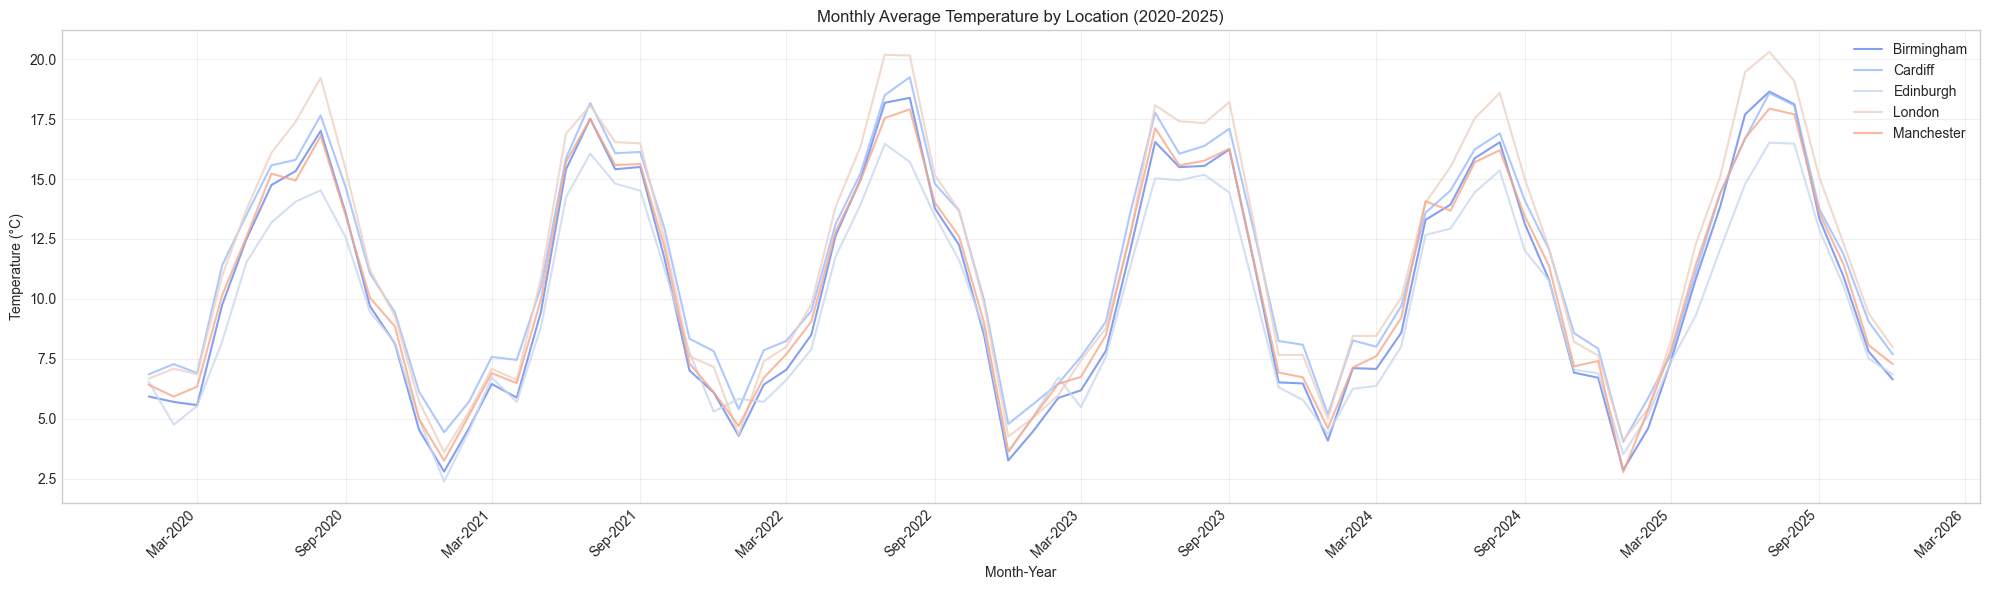

In [ ]:
import matplotlib.dates as mdates

# Create year-month column
df['year_month'] = pd.to_datetime(df['year'].astype(str) + '-' + df['month'].astype(str) + '-01')

# Calculate monthly average by location
monthly_data = df.groupby(['year_month', 'location'])['temperature_2m'].mean().reset_index()

# Plot
fig, ax = plt.subplots(figsize=(20, 6))

for location in monthly_data['location'].unique():
    loc_data = monthly_data[monthly_data['location'] == location]
    ax.plot(loc_data['year_month'], loc_data['temperature_2m'], linewidth=1.5, label=location, alpha=0.8)

# Format x-axis to show Jan-2020, Apr-2020, etc.
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))  # Every 6 months
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b-%Y'))  # e.g., Jan-2020
plt.xticks(rotation=45, ha='right')

plt.title('Monthly Average Temperature by Location (2020-2025)')
plt.xlabel('Month-Year')
plt.ylabel('Temperature (°C)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

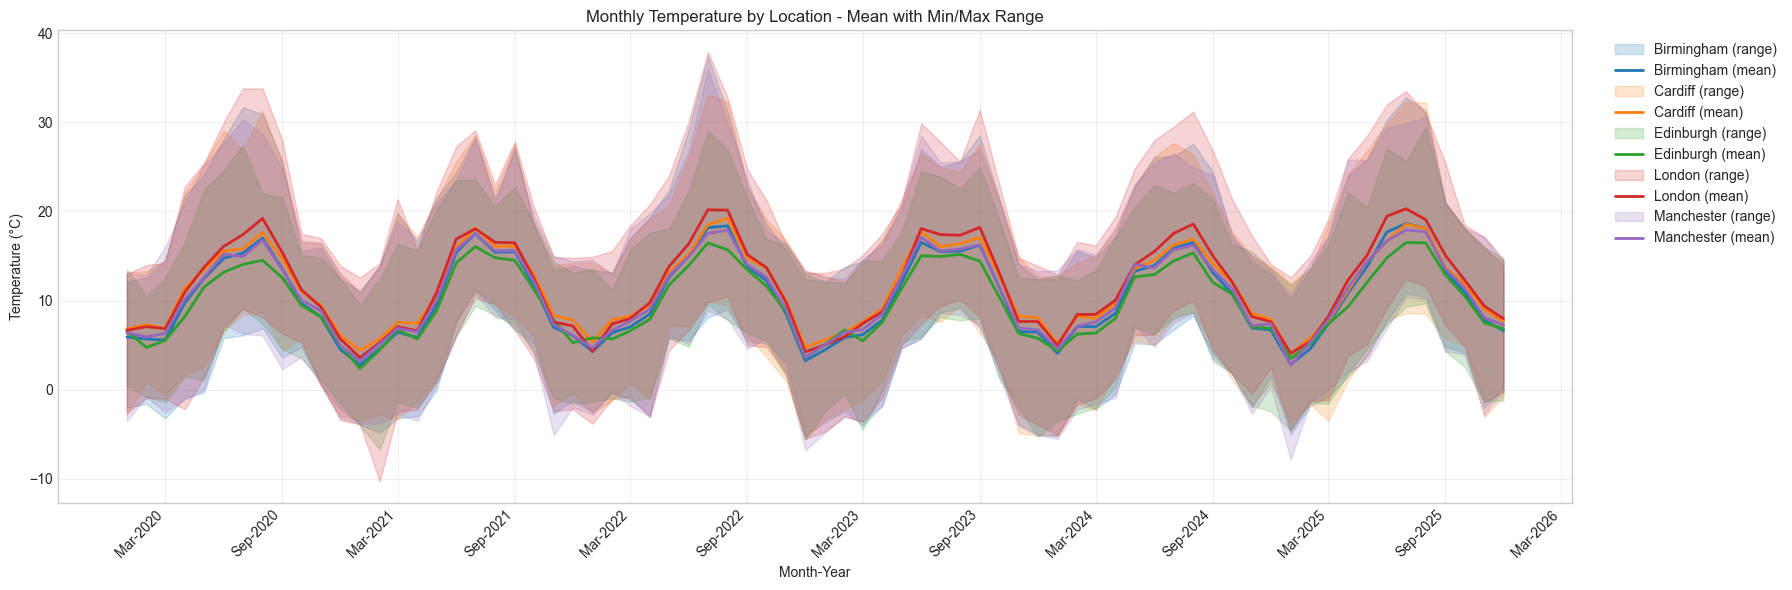

In [ ]:
import matplotlib.dates as mdates

# Create year-month column
df['year_month'] = pd.to_datetime(df['year'].astype(str) + '-' + df['month'].astype(str) + '-01')

# Calculate monthly stats by location
monthly_data = df.groupby(['year_month', 'location'])['temperature_2m'].agg(['mean', 'min', 'max']).reset_index()

# Plot
fig, ax = plt.subplots(figsize=(18, 6))

colors = plt.cm.tab10.colors

for i, location in enumerate(monthly_data['location'].unique()):
    loc_data = monthly_data[monthly_data['location'] == location].sort_values('year_month')
    
    # Shaded area for min/max range
    ax.fill_between(
        loc_data['year_month'], 
        loc_data['min'], 
        loc_data['max'], 
        alpha=0.2, 
        color=colors[i],
        label=f'{location} (range)'
    )
    
    # Mean line
    ax.plot(
        loc_data['year_month'], 
        loc_data['mean'], 
        linewidth=2, 
        color=colors[i], 
        label=f'{location} (mean)'
    )

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b-%Y'))
plt.xticks(rotation=45, ha='right')

plt.title('Monthly Temperature by Location - Mean with Min/Max Range')
plt.xlabel('Month-Year')
plt.ylabel('Temperature (°C)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

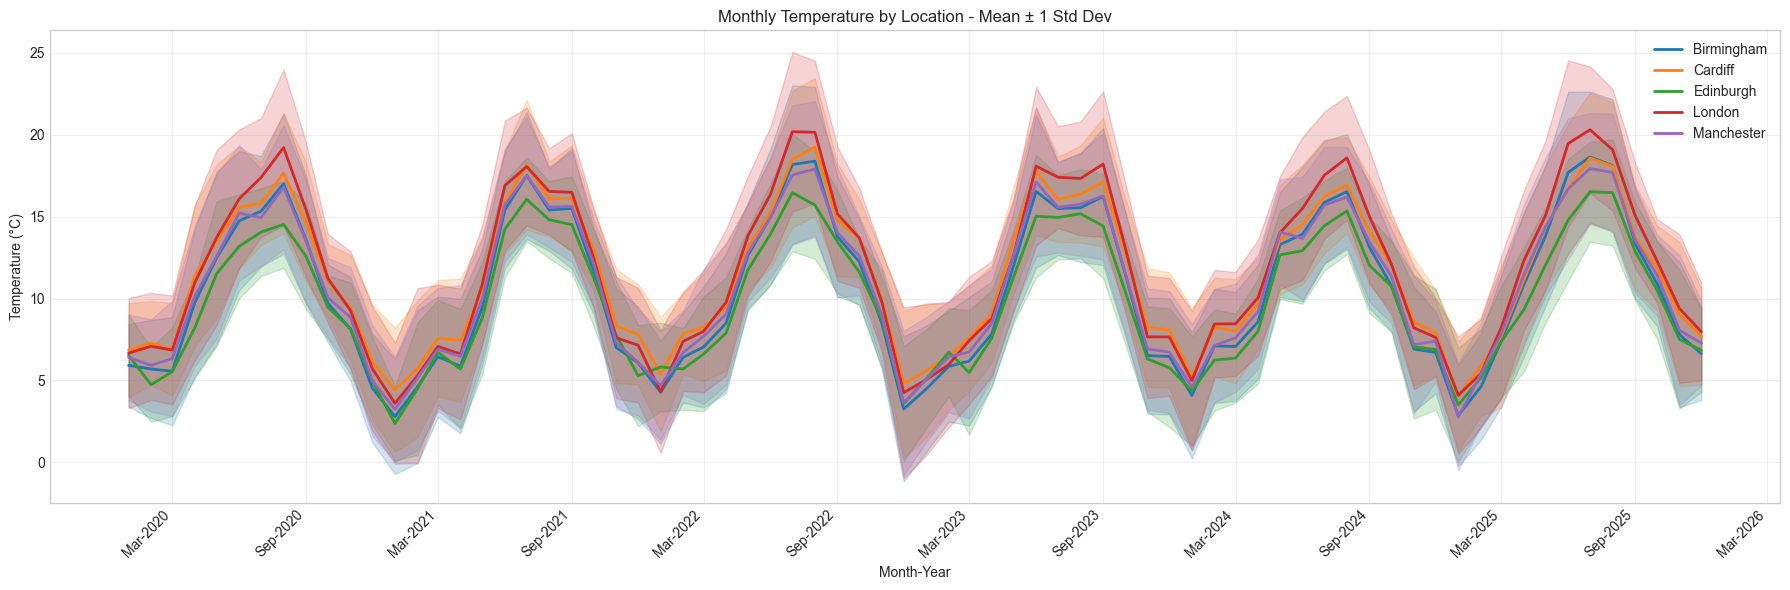

In [ ]:
import matplotlib.dates as mdates

# Create year-month column
df['year_month'] = pd.to_datetime(df['year'].astype(str) + '-' + df['month'].astype(str) + '-01')

# Calculate monthly stats
monthly_data = df.groupby(['year_month', 'location'])['temperature_2m'].agg(['mean', 'std']).reset_index()
monthly_data['lower'] = monthly_data['mean'] - monthly_data['std']
monthly_data['upper'] = monthly_data['mean'] + monthly_data['std']

# Plot
fig, ax = plt.subplots(figsize=(18, 6))

colors = plt.cm.tab10.colors

for i, location in enumerate(monthly_data['location'].unique()):
    loc_data = monthly_data[monthly_data['location'] == location].sort_values('year_month')
    
    # Shaded confidence band (±1 std dev)
    ax.fill_between(
        loc_data['year_month'], 
        loc_data['lower'], 
        loc_data['upper'], 
        alpha=0.2, 
        color=colors[i]
    )
    
    # Mean line
    ax.plot(
        loc_data['year_month'], 
        loc_data['mean'], 
        linewidth=2, 
        color=colors[i], 
        label=location
    )

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b-%Y'))
plt.xticks(rotation=45, ha='right')

plt.title('Monthly Temperature by Location - Mean ± 1 Std Dev')
plt.xlabel('Month-Year')
plt.ylabel('Temperature (°C)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

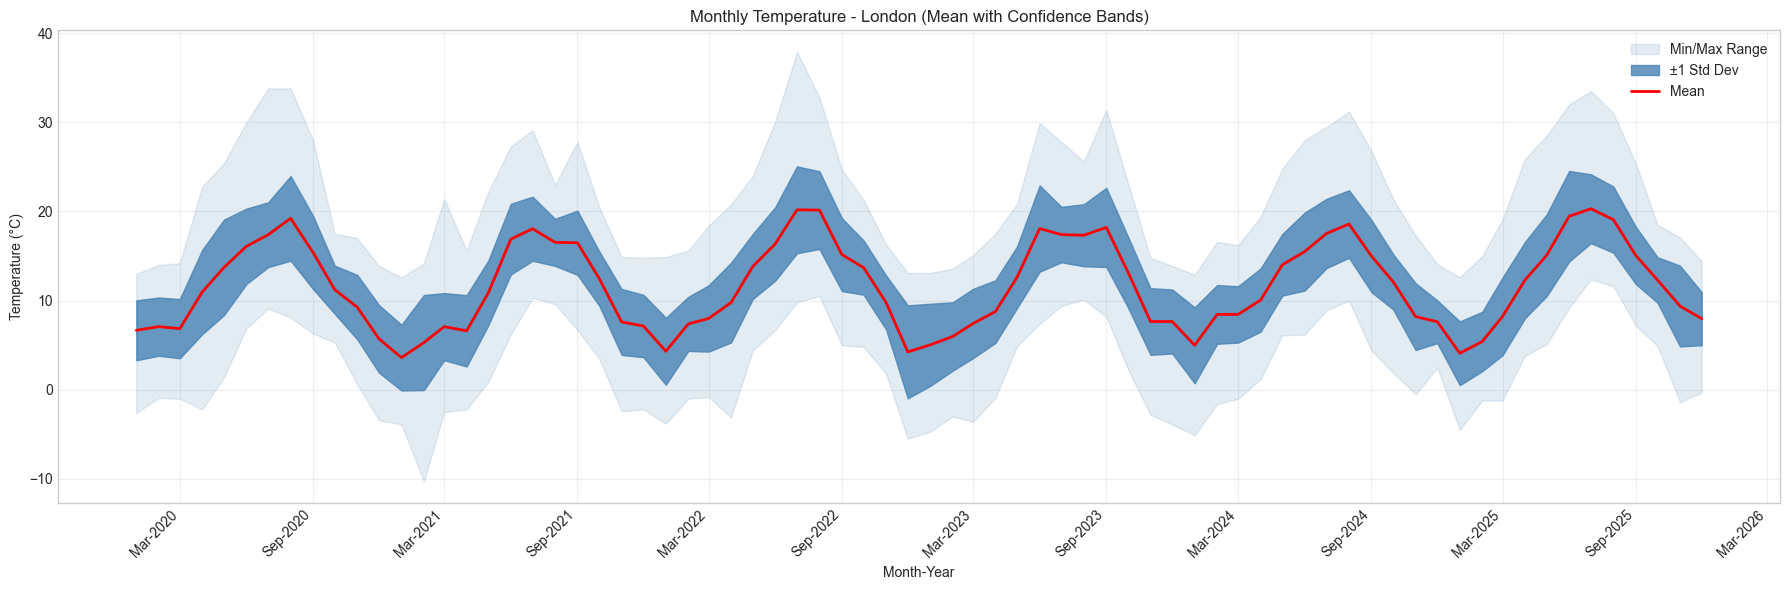

In [ ]:
import matplotlib.dates as mdates

# Filter to one location
location = 'London'
loc_df = df[df['location'] == location].copy()

# Create year-month
loc_df['year_month'] = pd.to_datetime(loc_df['year'].astype(str) + '-' + loc_df['month'].astype(str) + '-01')

# Calculate stats
monthly = loc_df.groupby('year_month')['temperature_2m'].agg(['mean', 'min', 'max', 'std']).reset_index()
monthly['lower'] = monthly['mean'] - monthly['std']
monthly['upper'] = monthly['mean'] + monthly['std']

# Plot
fig, ax = plt.subplots(figsize=(18, 6))

# Min/Max range (light)
ax.fill_between(monthly['year_month'], monthly['min'], monthly['max'], 
                alpha=0.15, color='steelblue', label='Min/Max Range')

# ±1 Std Dev (darker)
ax.fill_between(monthly['year_month'], monthly['lower'], monthly['upper'], 
                alpha=0.8, color='steelblue', label='±1 Std Dev')

# Mean line
ax.plot(monthly['year_month'], monthly['mean'], 
        linewidth=2, color='Red', label='Mean')

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b-%Y'))
plt.xticks(rotation=45, ha='right')

plt.title(f'Monthly Temperature - {location} (Mean with Confidence Bands)')
plt.xlabel('Month-Year')
plt.ylabel('Temperature (°C)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

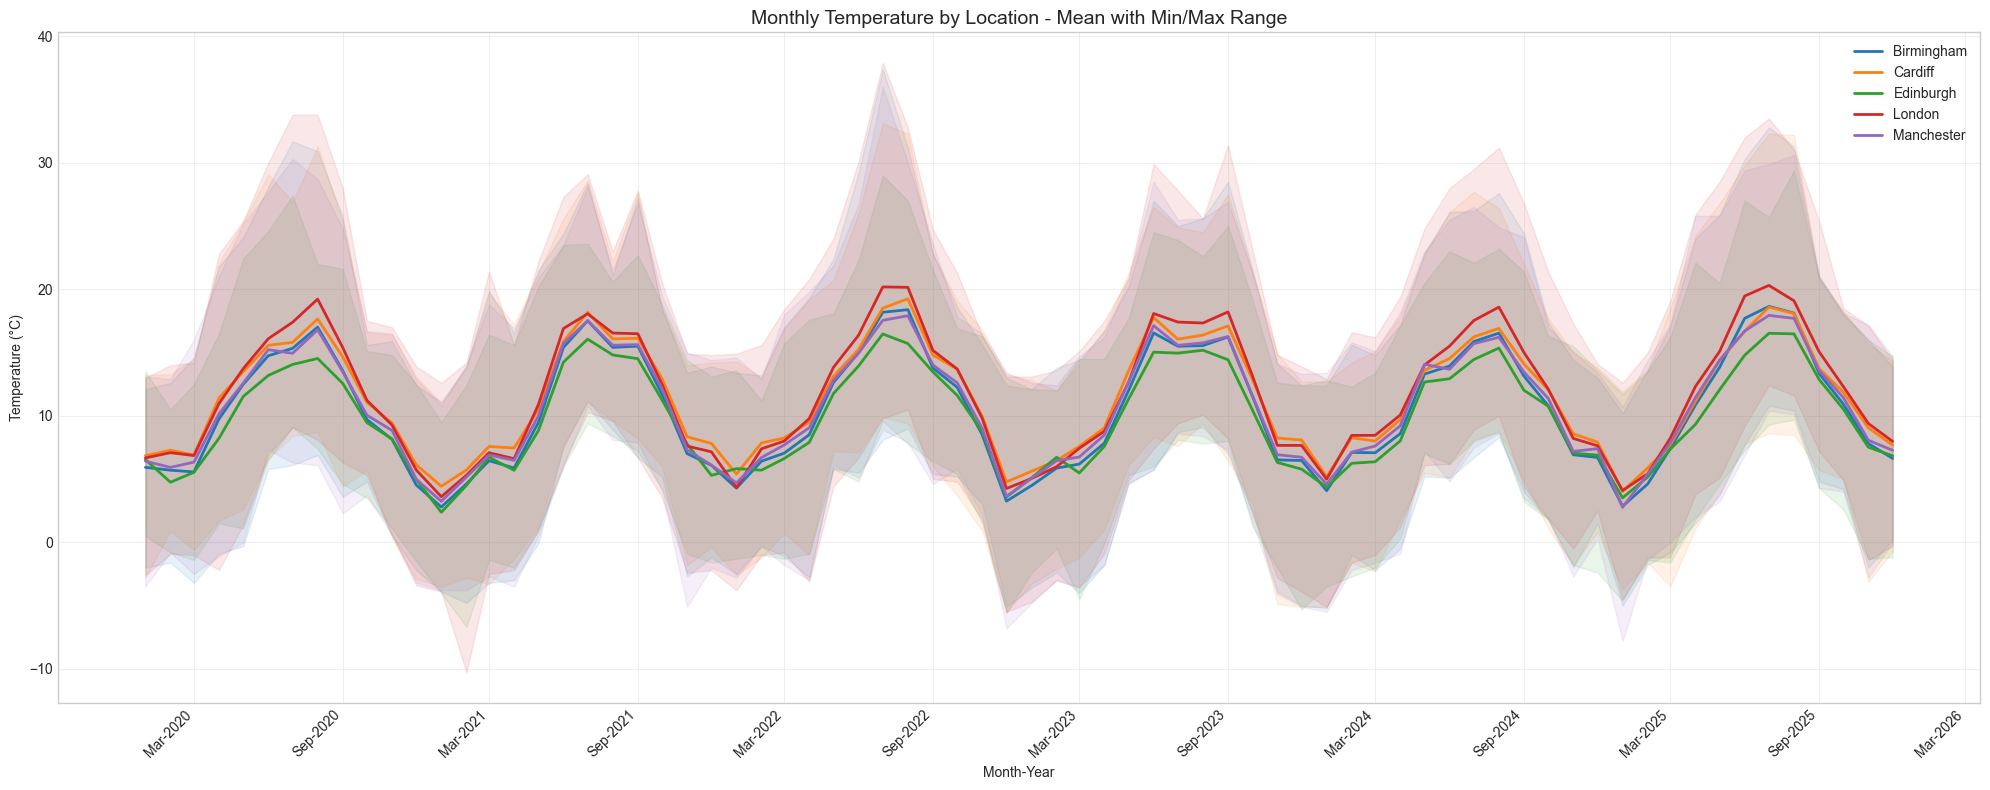

In [ ]:
import matplotlib.dates as mdates

# Create year-month
df['year_month'] = pd.to_datetime(df['year'].astype(str) + '-' + df['month'].astype(str) + '-01')

# Calculate stats
monthly_data = df.groupby(['year_month', 'location'])['temperature_2m'].agg(['mean', 'min', 'max']).reset_index()

# Plot
fig, ax = plt.subplots(figsize=(20, 8))

colors = {'Birmingham': '#1f77b4', 'Cardiff': '#ff7f0e', 'Edinburgh': '#2ca02c', 
          'London': '#d62728', 'Manchester': '#9467bd'}

for location in monthly_data['location'].unique():
    loc_data = monthly_data[monthly_data['location'] == location].sort_values('year_month')
    color = colors.get(location, 'gray')
    
    # Min/Max range (light shading)
    ax.fill_between(
        loc_data['year_month'], 
        loc_data['min'], 
        loc_data['max'], 
        alpha=0.1, 
        color=color,
    )
    
    # Mean line
    ax.plot(
        loc_data['year_month'], 
        loc_data['mean'], 
        linewidth=2, 
        color=color, 
        label=location
    )

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b-%Y'))
plt.xticks(rotation=45, ha='right')

plt.title('Monthly Temperature by Location - Mean with Min/Max Range', fontsize=14)
plt.xlabel('Month-Year')
plt.ylabel('Temperature (°C)')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pandas as pd

# Create year-month
df['year_month'] = pd.to_datetime(df['year'].astype(str) + '-' + df['month'].astype(str) + '-01')

# Calculate stats - all locations and per location
monthly_all = df.groupby('year_month')['temperature_2m'].mean().reset_index()
monthly_all.columns = ['year_month', 'all_mean']

monthly_data = df.groupby(['year_month', 'location'])['temperature_2m'].agg(['mean', 'min', 'max']).reset_index()
monthly_data = monthly_data.merge(monthly_all, on='year_month')

# Get locations
locations = monthly_data['location'].unique()
n_locations = len(locations)

# Create subplots - vertical stack
fig = make_subplots(
    rows=n_locations, 
    cols=1,
    shared_xaxes=True,
    shared_yaxes=True,
    vertical_spacing=0.05,
    subplot_titles=locations
)

for i, location in enumerate(locations):
    loc_data = monthly_data[monthly_data['location'] == location].sort_values('year_month')
    row = i + 1
    
    # Min/Max range (shaded area)
    fig.add_trace(
        go.Scatter(
            x=pd.concat([loc_data['year_month'], loc_data['year_month'][::-1]]),
            y=pd.concat([loc_data['max'], loc_data['min'][::-1]]),
            fill='toself',
            fillcolor='rgba(70, 130, 180, 0.2)',
            line=dict(color='rgba(255,255,255,0)'),
            name='Min/Max Range',
            showlegend=(i == 0),
            hoverinfo='skip'
        ),
        row=row, col=1
    )
    
    # UK Average reference line
    fig.add_trace(
        go.Scatter(
            x=loc_data['year_month'],
            y=loc_data['all_mean'],
            mode='lines',
            line=dict(color='grey', width=1, dash='dash'),
            name='UK Average',
            showlegend=(i == 0),
            hovertemplate='UK Avg: %{y:.1f}°C<extra></extra>'
        ),
        row=row, col=1
    )
    
    # Location mean line
    fig.add_trace(
        go.Scatter(
            x=loc_data['year_month'],
            y=loc_data['mean'],
            mode='lines',
            line=dict(color='steelblue', width=2),
            name=location,
            showlegend=False,
            hovertemplate=(
                f'<b>{location}</b><br>' +
                'Date: %{x|%b %Y}<br>' +
                'Mean: %{y:.1f}°C<br>' +
                '<extra></extra>'
            )
        ),
        row=row, col=1
    )
    
    # Add min/max to hover with invisible traces
    fig.add_trace(
        go.Scatter(
            x=loc_data['year_month'],
            y=loc_data['max'],
            mode='lines',
            line=dict(color='rgba(0,0,0,0)'),
            showlegend=False,
            hovertemplate='Max: %{y:.1f}°C<extra></extra>'
        ),
        row=row, col=1
    )
    
    fig.add_trace(
        go.Scatter(
            x=loc_data['year_month'],
            y=loc_data['min'],
            mode='lines',
            line=dict(color='rgba(0,0,0,0)'),
            showlegend=False,
            hovertemplate='Min: %{y:.1f}°C<extra></extra>'
        ),
        row=row, col=1
    )

# Update layout
fig.update_layout(
    title='Monthly Temperature by Location vs UK Average',
    height=250 * n_locations,
    width=1200,
    hovermode='x unified',
    legend=dict(
        orientation='h',
        yanchor='bottom',
        y=1.02,
        xanchor='center',
        x=0.5
    )
)

# Update axes
fig.update_xaxes(title_text='Year-Month', row=n_locations, col=1)
fig.update_yaxes(title_text='Temp (°C)', row=3, col=1)

fig.show()

In [ ]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pandas as pd

# Create month-year columns
df['month_name'] = pd.to_datetime(df['month'], format='%m').dt.strftime('%b')

# Calculate monthly average by location and year
monthly_data = df.groupby(['month', 'month_name', 'year', 'location'])['temperature_2m'].mean().reset_index()

# Get unique values
locations = monthly_data['location'].unique()
years = sorted(monthly_data['year'].unique())
months_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

# Color scale for years (cool to warm)
colors = {
    2020: '#3182bd',
    2021: '#6baed6', 
    2022: '#9ecae1',
    2023: '#fdae6b',
    2024: '#f16913',
    2025: '#d62728'
}

# Create subplots - one per location
fig = make_subplots(
    rows=2, cols=3,
    subplot_titles=locations,
    shared_yaxes=True,
    horizontal_spacing=0.05,
    vertical_spacing=0.12
)

for i, location in enumerate(locations):
    row = i // 3 + 1
    col = i % 3 + 1
    
    loc_data = monthly_data[monthly_data['location'] == location]
    
    for year in years:
        year_data = loc_data[loc_data['year'] == year].sort_values('month')
        
        fig.add_trace(
            go.Scatter(
                x=year_data['month_name'],
                y=year_data['temperature_2m'],
                mode='lines+markers',
                name=str(year),
                line=dict(color=colors.get(year, 'gray'), width=2),
                marker=dict(size=6),
                showlegend=(i == 0),
                hovertemplate=(
                    f'<b>{location} - {year}</b><br>' +
                    'Month: %{x}<br>' +
                    'Temp: %{y:.1f}°C<extra></extra>'
                )
            ),
            row=row, col=col
        )

fig.update_layout(
    title='Monthly Temperature Cohort Analysis - Year over Year by Location',
    height=600,
    width=1200,
    hovermode='x',
    legend=dict(
        title='Year',
        orientation='h',
        yanchor='bottom',
        y=1.02,
        xanchor='center',
        x=0.5
    )
)

fig.update_xaxes(categoryorder='array', categoryarray=months_order)
fig.update_yaxes(title_text='Temp (°C)', col=1)

fig.show()

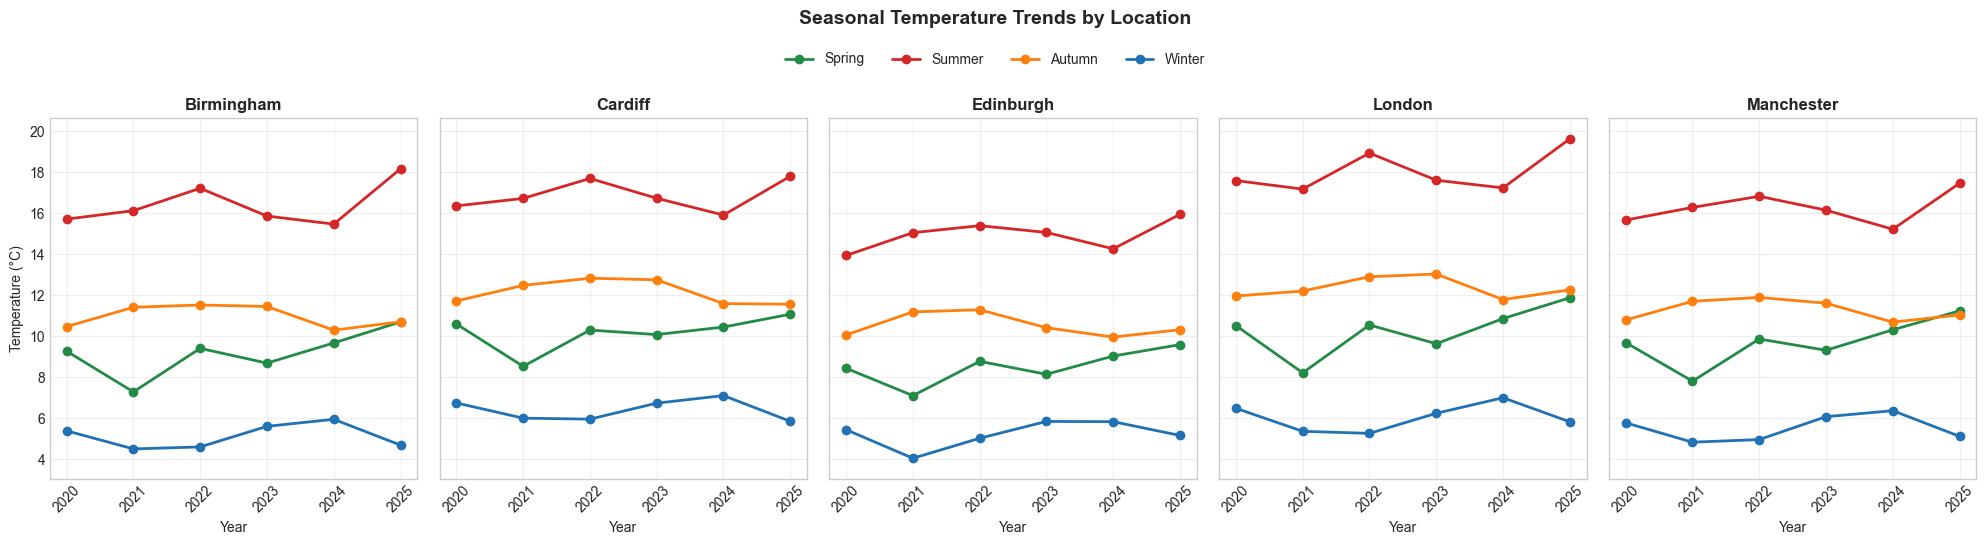

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Define seasons
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Autumn'

df['season'] = df['month'].apply(get_season)

# Calculate seasonal average by location and year
seasonal_data = df.groupby(['season', 'year', 'location'])['temperature_2m'].agg(['mean', 'min', 'max']).reset_index()

# Order seasons
season_order = ['Spring', 'Summer', 'Autumn', 'Winter']

# Get locations
locations = seasonal_data['location'].unique()
n_locations = len(locations)

# Colors for seasons
season_colors = {
    'Winter': '#2171b5',
    'Spring': '#238b45', 
    'Summer': '#d62728',
    'Autumn': '#ff7f0e'
}

# Create subplots - all on one row, shared y-axis
fig, axes = plt.subplots(1, n_locations, figsize=(20, 5), sharey=True)

# Get global y-axis limits for consistency
y_min = seasonal_data['mean'].min() - 1
y_max = seasonal_data['mean'].max() + 1

for i, location in enumerate(locations):
    ax = axes[i]
    loc_data = seasonal_data[seasonal_data['location'] == location]
    
    for season in season_order:
        season_data = loc_data[loc_data['season'] == season].sort_values('year')
        
        ax.plot(
            season_data['year'],
            season_data['mean'],
            marker='o',
            linewidth=2,
            markersize=6,
            color=season_colors[season],
            label=season if i == 0 else ''  # Only show legend for first subplot
        )
    
    ax.set_title(location, fontsize=12, fontweight='bold')
    ax.set_xlabel('Year')
    ax.set_ylim(y_min, y_max)
    ax.grid(True, alpha=0.3)
    ax.set_xticks(seasonal_data['year'].unique())
    ax.tick_params(axis='x', rotation=45)

# Y-axis label only on first subplot
axes[0].set_ylabel('Temperature (°C)')

# Single legend for all subplots
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=4, bbox_to_anchor=(0.5, 1.02))

plt.suptitle('Seasonal Temperature Trends by Location', fontsize=14, fontweight='bold', y=1.08)
plt.tight_layout()
plt.show()

In [ ]:
import plotly.express as px
import pandas as pd

# Define seasons
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Autumn'

df['season'] = df['month'].apply(get_season)

# Create season-year label
df['season_year'] = df['season'] + ' ' + df['year'].astype(str)

# Calculate average
seasonal_data = df.groupby(['season_year', 'season', 'year', 'location'])['temperature_2m'].mean().reset_index()

# Create pivot for heatmap
pivot = seasonal_data.pivot(index='location', columns='season_year', values='temperature_2m')

# Sort columns by year then season
season_order = ['Winter', 'Spring', 'Summer', 'Autumn']
years = sorted(df['year'].unique())
col_order = [f'{s} {y}' for y in years for s in season_order if f'{s} {y}' in pivot.columns]
pivot = pivot[col_order]

# Plot
fig = px.imshow(
    pivot,
    color_continuous_scale='RdYlBu_r',
    aspect='auto',
    labels=dict(x='Season-Year', y='Location', color='Temp (°C)')
)

fig.update_layout(
    title='Seasonal Temperature Heatmap by Location',
    height=400,
    width=1400,
    xaxis=dict(tickangle=45)
)

fig.show()